# 06 — MLP trên MNIST: đối chiếu bản tự cài đặt (NumPy) và thư viện (scikit-learn)

**Đồ án giữa kỳ môn Nhận dạng mẫu**

Notebook này là một thí nghiệm độc lập, chạy được từ đầu đến cuối, dùng để lấy **số liệu và hình ảnh trực tiếp cho báo cáo**. Ba phần chính:

1. **Kiểm chứng tính đúng đắn** của MLP viết tay trong `src/models/mlp.py` bằng hai cách độc lập:
   đạo hàm số (finite difference) và so sánh từng bước cập nhật với scikit-learn trên **cùng một điểm khởi tạo**.
2. **Đối chiếu thực nghiệm** hai cách huấn luyện trên cùng dữ liệu, cùng kiến trúc, cùng bộ tối ưu:
   chất lượng (accuracy, F1, log-loss), chi phí (thời gian, số tham số, suy luận), mức độ giống nhau của lỗi
   (McNemar, ensemble, calibration) và những gì mạng thực sự học được.
3. **Phân tích siêu tham số** có biểu đồ: learning rate, số lớp/nơ-ron, số vòng lặp, batch size, hệ số L2
   và số cây của RandomForest như một phép đối chiếu "ngân sách tính toán".

## Câu hỏi nghiên cứu

| Mã | Câu hỏi | Nơi trả lời |
|---|---|---|
| RQ1 | Công thức lan truyền ngược tự viết có **đúng** không? Sai số số học bao nhiêu? | §4 |
| RQ2 | Với cùng cấu hình, bản tự viết và thư viện khác nhau thế nào về **chất lượng và chi phí**? | §5.2–5.3 |
| RQ3 | Hai mô hình **sai giống hay khác** nhau? Chênh lệch có ý nghĩa thống kê? | §5.4–5.5 |
| RQ4 | **Siêu tham số** ảnh hưởng ra sao, và ảnh hưởng nào mạnh nhất? | §6 |
| RQ5 | Nên chọn cấu hình nào để đưa vào báo cáo, và cần lưu ý gì? | §7–8 |

## Cách đọc kết quả

* Mỗi hình đều có **tiêu đề nêu kết luận**, trục ghi rõ đơn vị; số liệu quan trọng được in ngay trên hình.
* Các bảng dùng chung một quy ước: accuracy/F1 là **tỉ lệ trong [0, 1]**, chênh lệch ghi theo dấu `+/-`.
* Sau mỗi thí nghiệm là một ô **nhận xét tự động** (Markdown) sinh ra từ chính số liệu vừa tính,
  nên khi chạy lại với seed khác, phần diễn giải vẫn khớp với kết quả.
* Hình lưu tại `results/figures/06_mlp_*.png`; số liệu tại `results/logs/06_mlp_summary.json` và
  `results/logs/06_mlp_experiments.csv`.

## Thiết lập dữ liệu và chi phí chạy

* MNIST: 60 000 ảnh train + 10 000 ảnh test, ảnh 28×28 được flatten thành 784 chiều và chuẩn hoá `[0, 1]`.
* Chia **54 000 train / 6 000 validation**; test chỉ dùng để báo cáo cuối, không dùng chọn mô hình.
* Thí nghiệm chính chạy đủ 54 000 mẫu, 20 epoch. Các thí nghiệm quét siêu tham số chạy trên tập con
  stratified **12 000 mẫu** để có thể quét nhiều giá trị và nhiều seed trong thời gian hợp lý.
* Toàn bộ notebook chạy trên CPU, khoảng **10–15 phút** (tùy máy). Seed mặc định `42`.

## 1. Thiết lập môi trường

Notebook tự tìm thư mục gốc của repo (nơi có `src/data.py`) nên chạy được dù kernel khởi động từ
`notebooks/` hay từ thư mục gốc. Các hàm tiện ích ở đây được dùng lại xuyên suốt notebook.

In [1]:
%matplotlib inline
import json
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import cohen_kappa_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier as SklearnMLP
import sklearn

warnings.filterwarnings("ignore")


def find_root() -> Path:
    here = Path.cwd().resolve()
    for cand in (here, *here.parents):
        if (cand / "src" / "data.py").exists():
            return cand
    raise RuntimeError("Không tìm thấy thư mục gốc chứa src/data.py")


ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import FIG_DIR, LOG_DIR, SEED
from src.data import load_prepared_mnist
from src.metrics import classification_metrics
from src.models.mlp import MLPClassifier
from src.utils import set_seed

set_seed(SEED)
FIG_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.axisbelow": True,
    "axes.unicode_minus": False,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

CUSTOM = "#1f77b4"   # MLP tự cài đặt
SKLEARN = "#d62728"  # MLP scikit-learn
GREEN = "#2ca02c"
GRAY = "#6c757d"

CFG = dict(
    hidden=(256, 128),
    lr=0.08,
    epochs=20,
    batch=256,
    l2=1e-4,
    n_sub=12_000,
    sub_epochs=6,
    probe=10_000,
    seeds=(42, 43, 44),
)

START = time.perf_counter()


def savefig(fig, name: str) -> Path:
    path = FIG_DIR / f"06_mlp_{name}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    return path


def show(df: pd.DataFrame, caption: str | None = None) -> None:
    if caption:
        display(Markdown(f"**{caption}**"))
    display(df)


def note(text: str) -> None:
    display(Markdown(text))


@contextmanager
def stopwatch():
    t0 = time.perf_counter()
    yield lambda: time.perf_counter() - t0


def ce_loss(proba: np.ndarray, y_idx: np.ndarray) -> float:
    return float(-np.mean(np.log(proba[np.arange(len(y_idx)), y_idx] + 1e-12)))


def count_params(weights, biases) -> int:
    return int(sum(w.size for w in weights) + sum(b.size for b in biases))


def bootstrap_ci(correct: np.ndarray, n_boot: int = 2000, seed: int = SEED):
    rng = np.random.default_rng(seed)
    n = len(correct)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        vals[b] = correct[idx].mean()
    return tuple(float(v) for v in np.percentile(vals, [2.5, 97.5]))


def bootstrap_diff_ci(correct_a: np.ndarray, correct_b: np.ndarray, n_boot: int = 2000, seed: int = SEED):
    rng = np.random.default_rng(seed)
    n = len(correct_a)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        vals[b] = correct_a[idx].mean() - correct_b[idx].mean()
    return tuple(float(v) for v in np.percentile(vals, [2.5, 97.5]))


def reliability(proba: np.ndarray, y_true: np.ndarray, n_bins: int = 10):
    conf = proba.max(axis=1)
    pred = proba.argmax(axis=1)
    hit = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        rows.append(dict(conf=float(conf[m].mean()), acc=float(hit[m].mean()), n=int(m.sum()), lo=lo, hi=hi))
    df = pd.DataFrame(rows)
    ece = float(np.sum(df["n"] / len(y_true) * np.abs(df["acc"] - df["conf"])))
    return df, ece


def time_predict(model, X: np.ndarray, repeats: int = 3) -> float:
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        _ = model.predict(X)
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


print(f"Thư mục gốc : {ROOT}")
print(f"Python      : {sys.version.split()[0]}")
print(f"NumPy       : {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Matplotlib  : {plt.matplotlib.__version__} | seed = {SEED}")
print("Thiết bị    : CPU")

Thư mục gốc : D:\midterm_pattern_recognition\mnist-pattern-recognition
Python      : 3.14.7
NumPy       : 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1
Matplotlib  : 3.11.2 | seed = 42
Thiết bị    : CPU


## 2. Dữ liệu và cách chia tập

Cách chia ba tầng dưới đây là điểm quan trọng để kết quả báo cáo **không bị rò rỉ**:

```
train gốc 60 000 ──┬─ 54 000  → huấn luyện mô hình chính
                   └─  6 000  → validation (chọn siêu tham số, theo dõi overfit)
test 10 000       →  chỉ dùng một lần để báo cáo chất lượng cuối
train_sub 12 000  →  tập con stratified của train, dùng cho các thí nghiệm quét
```

Vì mọi thí nghiệm quét ở §6 chỉ chọn mô hình theo **validation**, còn test chỉ được tính để tham khảo,
kết luận về cấu hình tốt nhất không bị "nhìn trước" tập test.

**Bảng 1 — Các tập dữ liệu**

,Tập,Số mẫu,Số đặc trưng,Số lớp,Mục đích
0,train,54000,784,10,huấn luyện mô hình chính
1,validation,6000,784,10,chọn siêu tham số
2,test,10000,784,10,báo cáo cuối
3,train_sub,12000,784,10,quét siêu tham số


Kiểu dữ liệu pixel: float32; miền giá trị: [0.0, 1.0]
Train: min 4,879 / max 6,068 mẫu mỗi lớp (lệch 1,189 mẫu do stratified split).


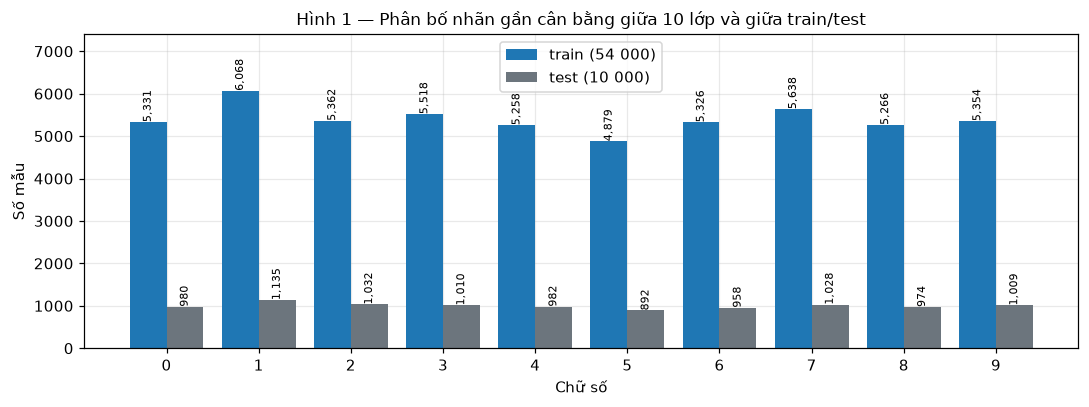

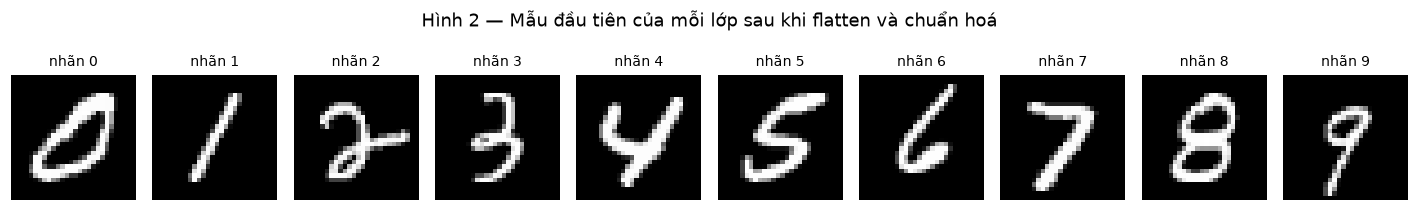


**Đọc dữ liệu.** Mỗi ảnh là vector 784 chiều, giá trị `[0, 1]`. Số mẫu mỗi lớp trong train nằm trong
khoảng **4,879–6,068**, nên accuracy là chỉ số tương đối công bằng;
tuy vậy báo cáo vẫn dùng thêm **F1 macro** để không bỏ qua lớp yếu nhất.


In [2]:
X_all, y_all, X_test, y_test = load_prepared_mnist()

X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.1, stratify=y_all, random_state=SEED
)
X_sub, _, y_sub, _ = train_test_split(
    X_tr, y_tr, train_size=CFG["n_sub"], stratify=y_tr, random_state=SEED
)

overview = pd.DataFrame([
    ["train", len(X_tr), X_tr.shape[1], len(np.unique(y_tr)), "huấn luyện mô hình chính"],
    ["validation", len(X_val), X_val.shape[1], len(np.unique(y_val)), "chọn siêu tham số"],
    ["test", len(X_test), X_test.shape[1], len(np.unique(y_test)), "báo cáo cuối"],
    ["train_sub", len(X_sub), X_sub.shape[1], len(np.unique(y_sub)), "quét siêu tham số"],
], columns=["Tập", "Số mẫu", "Số đặc trưng", "Số lớp", "Mục đích"])
show(overview, "Bảng 1 — Các tập dữ liệu")

counts_tr = np.bincount(y_tr, minlength=10)
counts_te = np.bincount(y_test, minlength=10)
print(f"Kiểu dữ liệu pixel: {X_tr.dtype}; miền giá trị: [{X_tr.min():.1f}, {X_tr.max():.1f}]")
print(f"Train: min {counts_tr.min():,} / max {counts_tr.max():,} mẫu mỗi lớp "
      f"(lệch {counts_tr.max() - counts_tr.min():,} mẫu do stratified split).")

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(10)
w = 0.4
ax.bar(x - w / 2, counts_tr, w, color=CUSTOM, label="train (54 000)")
ax.bar(x + w / 2, counts_te, w, color=GRAY, label="test (10 000)")
for xi, (a, b) in enumerate(zip(counts_tr, counts_te)):
    ax.text(xi - w / 2, a + 60, f"{a:,}", ha="center", fontsize=7, rotation=90)
    ax.text(xi + w / 2, b + 60, f"{b:,}", ha="center", fontsize=7, rotation=90)
ax.set_xticks(x)
ax.set_xlabel("Chữ số")
ax.set_ylabel("Số mẫu")
ax.set_ylim(0, counts_tr.max() * 1.22)
ax.set_title("Hình 1 — Phân bố nhãn gần cân bằng giữa 10 lớp và giữa train/test")
ax.legend()
fig.tight_layout()
savefig(fig, "01_class_distribution")
plt.show()

fig, axes = plt.subplots(1, 10, figsize=(13, 1.9))
for digit in range(10):
    idx = np.flatnonzero(y_tr == digit)[0]
    axes[digit].imshow(X_tr[idx].reshape(28, 28), cmap="gray")
    axes[digit].set_title(f"nhãn {digit}", fontsize=9)
    axes[digit].axis("off")
fig.suptitle("Hình 2 — Mẫu đầu tiên của mỗi lớp sau khi flatten và chuẩn hoá", y=1.02)
fig.tight_layout()
savefig(fig, "02_samples")
plt.show()

note(f'''
**Đọc dữ liệu.** Mỗi ảnh là vector 784 chiều, giá trị `[0, 1]`. Số mẫu mỗi lớp trong train nằm trong
khoảng **{counts_tr.min():,}–{counts_tr.max():,}**, nên accuracy là chỉ số tương đối công bằng;
tuy vậy báo cáo vẫn dùng thêm **F1 macro** để không bỏ qua lớp yếu nhất.
''')

# --------------------------------------------------------------------------

## 3. Cơ sở toán học và các quy ước cần khớp

### 3.1 Kiến trúc và lan truyền

Với mạng `784 → h₁ → … → h_L → 10` (ReLU ở lớp ẩn, Softmax ở lớp ra):

$$a^{(0)}=x,\qquad z^{(l)}=a^{(l-1)}W^{(l)}+b^{(l)},\qquad a^{(l)}=\max(0,z^{(l)}),$$
$$p=\operatorname{softmax}(z^{(L+1)}),\qquad \mathcal{L}=-\frac{1}{B}\sum_{i=1}^{B}\log p_{i,y_i}+\frac{\lambda}{2}\sum_l\lVert W^{(l)}\rVert_F^2 .$$

Nhờ đạo hàm của Softmax + cross-entropy triệt tiêu, delta lớp ra rất gọn:

$$\delta^{(L+1)}=p-\operatorname{onehot}(y),\qquad
\delta^{(l)}=\big(\delta^{(l+1)}W^{(l+1)\top}\big)\odot\mathbb{1}[z^{(l)}>0],$$
$$\nabla_{W^{(l)}}=a^{(l-1)\top}\delta^{(l)}+\lambda W^{(l)},\qquad
\nabla_{b^{(l)}}=\sum_i\delta_i^{(l)}.$$

### 3.2 Hai điểm dễ làm phép so sánh mất công bằng

1. **Khởi tạo.** `src/models/mlp.py` dùng He normal $\mathcal{N}(0,\sqrt{2/n_{in}})$ — phù hợp ReLU.
   scikit-learn mặc định dùng Glorot uniform. Hai cách khởi tạo cho hai quỹ đạo khác nhau dù cùng thuật toán.
2. **Quy ước chuẩn hoá L2.** Trong `src/models/mlp.py`, gradient cộng `l2 * W` **không chia batch**.
   Trong scikit-learn, `coef_grads = (Aᵀδ + alpha·W) / B`, tức **chia cho batch**. Suy ra:

$$\boxed{\alpha_{\text{sklearn}}=\lambda\times B}$$

Với $\lambda=10^{-4}$ và $B=256$, `alpha` tương đương là **0.0256**, lớn hơn 256 lần giá trị mặc định
`alpha=1e-4`. §4.3 sẽ kiểm chứng đẳng thức này bằng số.

| Thành phần | `src/models/mlp.py` | scikit-learn |
|---|---|---|
| Kiến trúc | `hidden_units=(256,128)` | `hidden_layer_sizes=(256,128)` |
| Kích hoạt | ReLU + Softmax | `activation='relu'`, log-loss |
| Tối ưu | SGD thuần | `solver='sgd'`, `learning_rate='constant'`, `momentum=0` |
| Minibatch | `batch_size=256` | `batch_size=256`, `shuffle=True` |
| L2 | `l2=1e-4` | `alpha=1e-4 × 256 = 0.0256` |
| Khởi tạo | He normal | Glorot uniform (mặc định) |
| Kiểu số | `float64` | `float32` |

## 4. Kiểm chứng bản tự cài đặt

### 4.1 Kiểm tra đạo hàm bằng sai phân hữu hạn

Ý tưởng: với một mạng nhỏ `784 → 6 → 10`, lấy một điểm khởi tạo ngẫu nhiên, tính gradient giải tích
bằng chính `_backward`, rồi so với đạo hàm số trung tâm:

$$\frac{\partial\mathcal{L}}{\partial\theta}\approx\frac{\mathcal{L}(\theta+\varepsilon)-\mathcal{L}(\theta-\varepsilon)}{2\varepsilon}.$$

Nếu công thức đúng, sai số tương đối phải ở mức $10^{-5}$ trở xuống với `float64` và $\varepsilon=10^{-5}$
(các gradient rất nhỏ có thể nhạy hơn với nhiễu làm tròn, nên cũng báo cáo cả sai số tuyệt đối).
Chỉ số được lấy mẫu ngẫu nhiên **25 trọng số + 8 bias mỗi lớp** để giữ chi phí thấp nhưng vẫn phủ cả hai lớp.

**Bảng 2 — Sai số đạo hàm số so với gradient giải tích**

,Lớp,Loại,Số điểm,Sai số tuyệt đối lớn nhất,Sai số tương đối lớn nhất,Trung vị sai số tương đối
0,ẩn 784→6,Trọng số W,25,0.0,1.731800e-06,1.330000e-08
1,ẩn 784→6,Bias b,8,0.0,2.900000e-09,1.000000e-10
2,ra 6→10,Trọng số W,25,0.0,2.690000e-08,9.000000e-10
3,ra 6→10,Bias b,8,0.0,5.400000e-09,1.000000e-10


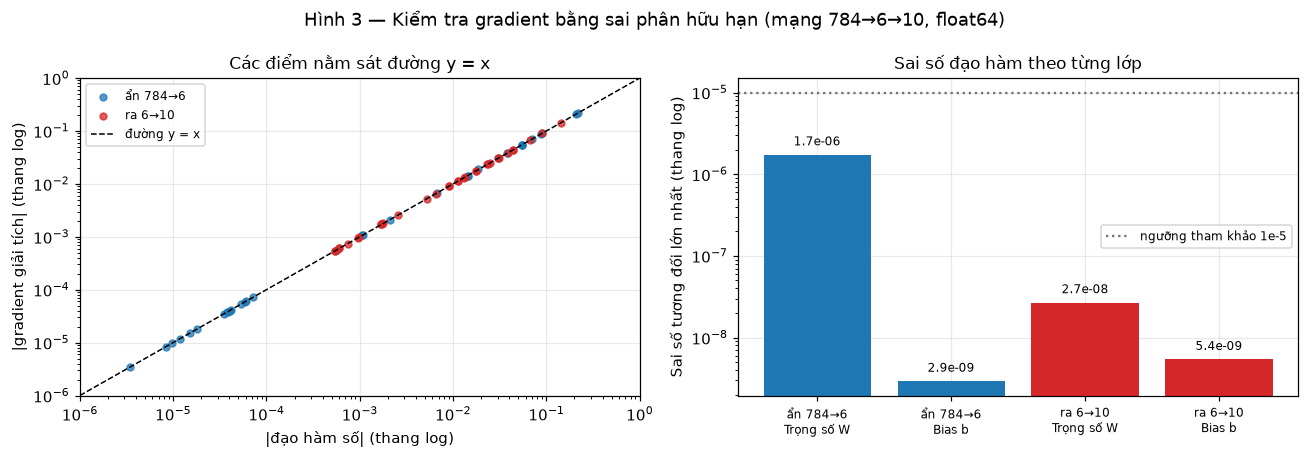


**Kết luận 4.1.** Sai số tương đối lớn nhất là **1.73e-06** (dưới ngưỡng tham khảo $10^-5$),
trung vị **1.03e-09**, sai số tuyệt đối lớn nhất **3.24e-11**. Toàn bộ điểm nằm sát
đường $y=x$; sai số chỉ là nhiễu làm tròn của `float64` và của phép trừ hai số gần nhau. Công thức
`_backward` (gồm cả số hạng L2) là **đúng về mặt giải tích**.


In [3]:
rng_grad = np.random.default_rng(7)
n_grad = 64
Xg = np.asarray(X_tr[:n_grad], dtype=np.float64)
yg = y_tr[:n_grad]

grad_net = MLPClassifier(hidden_units=(6,), learning_rate=1.0, epochs=1,
                         batch_size=n_grad, l2=1e-3, seed=1)
grad_net.classes_, yg_idx = np.unique(yg, return_inverse=True)
grad_net._init_para(Xg.shape[1], len(grad_net.classes_), rng_grad)

W0 = [w.copy() for w in grad_net.weights_]
b0 = [b.copy() for b in grad_net.biases_]
grad_net._backward(Xg, yg_idx)  # learning_rate=1 ⇒ ΔW = -gradient
gW = [W0[i] - grad_net.weights_[i] for i in range(len(W0))]
gb = [b0[i] - grad_net.biases_[i] for i in range(len(b0))]


def set_params(weights, biases):
    grad_net.weights_ = [w.copy() for w in weights]
    grad_net.biases_ = [b.copy() for b in biases]


EPS = 1e-5
records = []
layer_names = ["ẩn 784→6", "ra 6→10"]

for layer, layer_name in enumerate(layer_names):
    shape = W0[layer].shape
    for _ in range(25):
        i = int(rng_grad.integers(shape[0]))
        j = int(rng_grad.integers(shape[1]))
        Wp = [w.copy() for w in W0]
        Wm = [w.copy() for w in W0]
        Wp[layer][i, j] += EPS
        Wm[layer][i, j] -= EPS
        set_params(Wp, b0)
        lp = grad_net._loss(Xg, yg_idx)
        set_params(Wm, b0)
        lm = grad_net._loss(Xg, yg_idx)
        numeric = (lp - lm) / (2 * EPS)
        analytic = float(gW[layer][i, j])
        records.append(dict(layer=layer_name, kind="W", analytic=analytic, numeric=numeric))

    for _ in range(8):
        i = int(rng_grad.integers(shape[1]))
        bp = [b.copy() for b in b0]
        bm = [b.copy() for b in b0]
        bp[layer][i] += EPS
        bm[layer][i] -= EPS
        set_params(W0, bp)
        lp = grad_net._loss(Xg, yg_idx)
        set_params(W0, bm)
        lm = grad_net._loss(Xg, yg_idx)
        numeric = (lp - lm) / (2 * EPS)
        analytic = float(gb[layer][i])
        records.append(dict(layer=layer_name, kind="b", analytic=analytic, numeric=numeric))

set_params(W0, b0)

gdf = pd.DataFrame(records)
gdf["abs_err"] = (gdf["analytic"] - gdf["numeric"]).abs()
gdf["rel_err"] = gdf["abs_err"] / np.maximum(1e-12, gdf["analytic"].abs() + gdf["numeric"].abs())
gdf["Loại"] = gdf["kind"].map({"W": "Trọng số W", "b": "Bias b"})

grad_summary = (
    gdf.groupby(["layer", "Loại"], sort=False)
    .agg(n=("rel_err", "size"),
         max_abs=("abs_err", "max"),
         max_rel=("rel_err", "max"),
         median_rel=("rel_err", "median"))
    .reset_index()
    .rename(columns={
        "layer": "Lớp",
        "n": "Số điểm",
        "max_abs": "Sai số tuyệt đối lớn nhất",
        "max_rel": "Sai số tương đối lớn nhất",
        "median_rel": "Trung vị sai số tương đối",
    })
)
show(grad_summary.round(10), "Bảng 2 — Sai số đạo hàm số so với gradient giải tích")

color_map = {"ẩn 784→6": CUSTOM, "ra 6→10": SKLEARN}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for layer_name in layer_names:
    sub = gdf[(gdf["layer"] == layer_name) & (gdf["analytic"].abs() > 1e-10)]
    axes[0].scatter(np.abs(sub["numeric"]), np.abs(sub["analytic"]), s=20, alpha=0.75,
                    color=color_map[layer_name], label=layer_name)
lims = [1e-6, 1e0]
axes[0].plot(lims, lims, "k--", lw=1, label="đường y = x")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel("|đạo hàm số| (thang log)")
axes[0].set_ylabel("|gradient giải tích| (thang log)")
axes[0].set_title("Các điểm nằm sát đường y = x")
axes[0].legend(fontsize=8)

labels = [f"{r['Lớp']}\n{r['Loại']}" for _, r in grad_summary.iterrows()]
bars = axes[1].bar(range(len(grad_summary)),
                   np.maximum(grad_summary["Sai số tương đối lớn nhất"], 1e-12),
                   color=[CUSTOM if "ẩn" in lab else SKLEARN for lab in labels])
for bar, v in zip(bars, grad_summary["Sai số tương đối lớn nhất"]):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v * 1.3, f"{v:.1e}", ha="center", fontsize=8)
axes[1].set_yscale("log")
axes[1].axhline(1e-5, color=GRAY, ls=":", label="ngưỡng tham khảo 1e-5")
axes[1].set_xticks(range(len(grad_summary)))
axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylabel("Sai số tương đối lớn nhất (thang log)")
axes[1].set_title("Sai số đạo hàm theo từng lớp")
axes[1].legend(fontsize=8)
fig.suptitle("Hình 3 — Kiểm tra gradient bằng sai phân hữu hạn (mạng 784→6→10, float64)")
fig.tight_layout()
savefig(fig, "03_gradient_check")
plt.show()

GRAD_MAX_REL = float(gdf["rel_err"].max())
GRAD_MED_REL = float(gdf["rel_err"].median())
GRAD_MAX_ABS = float(gdf["abs_err"].max())

note(f'''
**Kết luận 4.1.** Sai số tương đối lớn nhất là **{GRAD_MAX_REL:.2e}** (dưới ngưỡng tham khảo $10^{-5}$),
trung vị **{GRAD_MED_REL:.2e}**, sai số tuyệt đối lớn nhất **{GRAD_MAX_ABS:.2e}**. Toàn bộ điểm nằm sát
đường $y=x$; sai số chỉ là nhiễu làm tròn của `float64` và của phép trừ hai số gần nhau. Công thức
`_backward` (gồm cả số hạng L2) là **đúng về mặt giải tích**.
''')

# --------------------------------------------------------------------------

### 4.2 So sánh từng bước cập nhật với scikit-learn trên cùng điểm khởi tạo

Kiểm tra đạo hàm đã chứng minh công thức; bước tiếp theo là chứng minh **toàn bộ quy trình cập nhật**
tương đương. Cách làm:

1. Huấn luyện một mạng nhỏ bằng scikit-learn để lấy bộ trọng số khởi tạo (Glorot).
2. Nạp đúng bộ trọng số đó vào MLP tự cài đặt.
3. Chạy **full-batch gradient descent** (batch = toàn bộ 2 000 mẫu), không xáo trộn, không momentum.
4. Sau mỗi bước, so sánh `max |ΔW|` và loss cross-entropy của hai mô hình.

Nếu hai bên cài đặt cùng một phép toán, quỹ đạo phải trùng nhau tới mức sai số dấu phẩy động.

**Bảng 3 — Đối chiếu từng bước, full-batch, không L2 (n = 2 000)**

,Bước GD,Loss tự cài đặt,Loss sklearn,|Δloss|,max |ΔW|
0,1,2.314469,2.314469,0.0,0.0
1,2,2.298039,2.298039,0.0,0.0
2,3,2.281835,2.281835,0.0,0.0
3,4,2.266021,2.266021,0.0,0.0
4,5,2.249847,2.249847,0.0,0.0
5,6,2.233638,2.233638,0.0,0.0
6,7,2.217405,2.217405,0.0,0.0
7,8,2.200828,2.200828,0.0,0.0


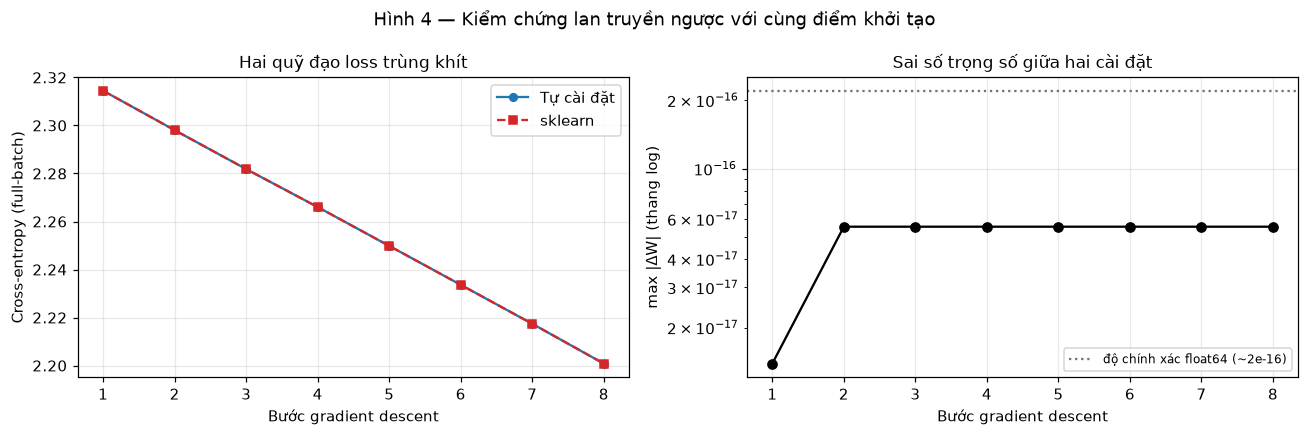


**Kết luận 4.2.** Sau **8 bước**, `max |ΔW| = 5.55e-17` và hai đường loss không thể phân biệt
trên hình. Đây là sai số làm tròn, không phải khác biệt thuật toán. Như vậy, nếu cùng điểm khởi tạo và
cùng thứ tự dữ liệu, bản tự viết và scikit-learn cho **cùng một quỹ đạo huấn luyện**.


In [4]:
N_EQ = 2_000
STEPS = 8
Xe = np.asarray(X_tr[:N_EQ], dtype=np.float64)
ye = y_tr[:N_EQ]
ye_idx = np.searchsorted(np.unique(ye), ye)

sk_ref = SklearnMLP(
    hidden_layer_sizes=(32, 16), solver="sgd", learning_rate="constant",
    learning_rate_init=0.1, batch_size=N_EQ, alpha=0.0, momentum=0.0,
    nesterovs_momentum=False, shuffle=False, tol=0.0, random_state=0, max_iter=1,
).fit(Xe, ye)

cu_ref = MLPClassifier(hidden_units=(32, 16), learning_rate=0.1, epochs=1,
                       batch_size=N_EQ, l2=0.0, seed=0)
cu_ref.weights_ = [w.copy() for w in sk_ref.coefs_]
cu_ref.biases_ = [b.copy() for b in sk_ref.intercepts_]
cu_ref.classes_ = np.unique(ye)

eq_rows = []
dw_values = []
loss_cu_curve = []
loss_sk_curve = []

for step in range(1, STEPS + 1):
    cu_ref._backward(Xe, ye_idx)
    sk_ref.partial_fit(Xe, ye, classes=np.arange(10))

    dw = max(float(np.abs(a - b).max()) for a, b in zip(cu_ref.weights_, sk_ref.coefs_))
    loss_cu = ce_loss(cu_ref.predict_proba(Xe), ye_idx)
    loss_sk = ce_loss(sk_ref.predict_proba(Xe), ye_idx)
    dw_values.append(dw)
    loss_cu_curve.append(loss_cu)
    loss_sk_curve.append(loss_sk)
    eq_rows.append([step, loss_cu, loss_sk, abs(loss_cu - loss_sk), dw])

eq_df = pd.DataFrame(eq_rows, columns=["Bước GD", "Loss tự cài đặt", "Loss sklearn", "|Δloss|", "max |ΔW|"])
show(eq_df.round(10), "Bảng 3 — Đối chiếu từng bước, full-batch, không L2 (n = 2 000)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
steps = np.arange(1, STEPS + 1)
axes[0].plot(steps, loss_cu_curve, "o-", color=CUSTOM, label="Tự cài đặt", ms=5)
axes[0].plot(steps, loss_sk_curve, "s--", color=SKLEARN, label="sklearn", ms=5)
axes[0].set_xlabel("Bước gradient descent")
axes[0].set_ylabel("Cross-entropy (full-batch)")
axes[0].set_title("Hai quỹ đạo loss trùng khít")
axes[0].legend()

axes[1].semilogy(steps, np.maximum(dw_values, 1e-18), "o-", color="black")
axes[1].axhline(2.2e-16, color=GRAY, ls=":", label="độ chính xác float64 (~2e-16)")
axes[1].set_xlabel("Bước gradient descent")
axes[1].set_ylabel("max |ΔW| (thang log)")
axes[1].set_title("Sai số trọng số giữa hai cài đặt")
axes[1].legend(fontsize=8)
fig.suptitle("Hình 4 — Kiểm chứng lan truyền ngược với cùng điểm khởi tạo")
fig.tight_layout()
savefig(fig, "04_equivalence")
plt.show()

DW_FINAL = float(dw_values[-1])

note(f'''
**Kết luận 4.2.** Sau **{STEPS} bước**, `max |ΔW| = {DW_FINAL:.2e}` và hai đường loss không thể phân biệt
trên hình. Đây là sai số làm tròn, không phải khác biệt thuật toán. Như vậy, nếu cùng điểm khởi tạo và
cùng thứ tự dữ liệu, bản tự viết và scikit-learn cho **cùng một quỹ đạo huấn luyện**.
''')

### 4.3 Kiểm chứng ánh xạ chuẩn hoá L2: $\alpha = \lambda B$

Thí nghiệm lặp lại 3 bước cập nhật với `l2 = 1e-4` ở bản tự viết, thử hai giá trị `alpha` của sklearn:

* `alpha = 1e-4` — giá trị mặc định, **không** khớp quy ước;
* `alpha = 1e-4 × 2000 = 0.2` — khớp công thức $\alpha=\lambda B$.

Nếu lý thuyết đúng, cấu hình thứ hai phải cho sai số ~$10^{-8}$, còn cấu hình thứ nhất lệch rõ rệt.

In [5]:
def l2_gap(alpha_sk: float, steps: int = 3) -> float:
    sk = SklearnMLP(
        hidden_layer_sizes=(32, 16), solver="sgd", learning_rate="constant",
        learning_rate_init=0.1, batch_size=N_EQ, alpha=alpha_sk, momentum=0.0,
        nesterovs_momentum=False, shuffle=False, tol=0.0, random_state=0, max_iter=1,
    ).fit(Xe, ye)
    cu = MLPClassifier(hidden_units=(32, 16), learning_rate=0.1, epochs=1,
                       batch_size=N_EQ, l2=1e-4, seed=0)
    cu.weights_ = [w.copy() for w in sk.coefs_]
    cu.biases_ = [b.copy() for b in sk.intercepts_]
    cu.classes_ = np.unique(ye)
    for _ in range(steps):
        cu._backward(Xe, ye_idx)
        sk.partial_fit(Xe, ye, classes=np.arange(10))
    return max(float(np.abs(a - b).max()) for a, b in zip(cu.weights_, sk.coefs_))


DW_ALPHA_DEFAULT = l2_gap(1e-4)
DW_ALPHA_MATCHED = l2_gap(1e-4 * N_EQ)

alpha_df = pd.DataFrame([
    ["Mặc định sklearn", "1e-4", DW_ALPHA_DEFAULT],
    ["Khớp công thức α = λ × B", f"{1e-4 * N_EQ:g}", DW_ALPHA_MATCHED],
], columns=["Cấu hình alpha", "alpha", "max |ΔW| sau 3 bước"])
show(alpha_df, "Bảng 4 — Kiểm chứng ánh xạ alpha ↔ l2 (λ = 1e-4, B = 2 000)")

note(f'''
**Kết luận 4.3.** Với `alpha` khớp công thức, sai số là **{DW_ALPHA_MATCHED:.2e}**; với `alpha` mặc định,
sai số là **{DW_ALPHA_DEFAULT:.2e}** — lệch **{DW_ALPHA_DEFAULT / max(DW_ALPHA_MATCHED, 1e-18):.0f} lần**.
Nếu bỏ qua chi tiết này, mô hình sklearn sẽ bị chuẩn hoá mạnh hơn 2 000 lần và phép so sánh ở §5
sẽ không còn công bằng.
''')

# --------------------------------------------------------------------------

**Bảng 4 — Kiểm chứng ánh xạ alpha ↔ l2 (λ = 1e-4, B = 2 000)**

,Cấu hình alpha,alpha,max |ΔW| sau 3 bước
0,Mặc định sklearn,1e-4,1.418300e-05
1,Khớp công thức α = λ × B,0.2,5.551115e-17



**Kết luận 4.3.** Với `alpha` khớp công thức, sai số là **5.55e-17**; với `alpha` mặc định,
sai số là **1.42e-05** — lệch **255498175773 lần**.
Nếu bỏ qua chi tiết này, mô hình sklearn sẽ bị chuẩn hoá mạnh hơn 2 000 lần và phép so sánh ở §5
sẽ không còn công bằng.


## 5. Đối chiếu trên toàn bộ dữ liệu train

### 5.1 Giao thức

| Thành phần | Giá trị |
|---|---|
| Dữ liệu huấn luyện | 54 000 mẫu |
| Kiến trúc | 784 → 256 → 128 → 10 (235 146 tham số) |
| Learning rate | 0.08, hằng số |
| Batch size | 256 |
| L2 | λ = 1e-4 ⇒ `alpha = 0.0256` |
| Số epoch | 20 |
| Theo dõi | loss/accuracy trên 10 000 mẫu probe và 6 000 mẫu validation sau mỗi epoch |

Để vẽ được đường cong theo epoch cho bản tự viết mà **không sửa thuật toán**, notebook định nghĩa
`TrackingMLP` kế thừa `MLPClassifier`, giữ nguyên `_init_para`, `_forward`, `_backward`, `_loss`,
chỉ thay vòng lặp `fit` bằng một vòng lặp y hệt có đo thêm chỉ số. Một phép kiểm tra ngay bên dưới
chứng minh lớp bọc này **trung tính**: trọng số sau huấn luyện trùng khít bản gốc.

Với scikit-learn, mỗi epoch được chạy bằng một lần `partial_fit` (`max_iter=1`) để có cùng thang đo
theo epoch. Cấu hình `shuffle=True`, `tol=0`, `early_stopping=False` bảo đảm chạy đủ 20 epoch.

In [6]:
class TrackingMLP(MLPClassifier):
    '''MLPClassifier + ghi lại loss/accuracy theo epoch; giữ nguyên logic huấn luyện gốc.'''

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=np.float64)
        self.classes_, y_idx = np.unique(y, return_inverse=True)
        rng = np.random.default_rng(self.seed)
        self._init_para(X.shape[1], len(self.classes_), rng)
        self.history_ = []

        n = len(X)
        probe_rng = np.random.default_rng(SEED + 991)  # RNG riêng, cố định giữa các seed
        probe = probe_rng.choice(n, size=min(CFG["probe"], n), replace=False)
        y_val_idx = None if X_val is None else np.searchsorted(self.classes_, y_val)

        self.probe_loss_, self.train_acc_, self.val_loss_, self.val_acc_, self.epoch_time_ = [], [], [], [], []

        for _ in range(self.epochs):
            t0 = time.perf_counter()
            perm = rng.permutation(n)
            for start in range(0, n, self.batch_size):
                idx = perm[start:start + self.batch_size]
                self._backward(X[idx], y_idx[idx])
            self.epoch_time_.append(time.perf_counter() - t0)

            proba_probe = self._forward(X[probe])[1]
            self.probe_loss_.append(ce_loss(proba_probe, y_idx[probe]))
            self.train_acc_.append(float(np.mean(np.argmax(proba_probe, 1) == y_idx[probe])))
            if X_val is not None:
                proba_val = self._forward(np.asarray(X_val, dtype=np.float64))[1]
                self.val_loss_.append(ce_loss(proba_val, y_val_idx))
                self.val_acc_.append(float(np.mean(np.argmax(proba_val, 1) == y_val_idx)))
        self.history_ = self.probe_loss_
        return self


def fit_sklearn_epochwise(X, y, X_val, y_val, probe, epochs, **kw):
    '''Huấn luyện sklearn MLP từng epoch bằng partial_fit, ghi chỉ số giống TrackingMLP.'''
    model = SklearnMLP(max_iter=1, **kw)
    classes = np.unique(y)
    hist = dict(probe_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    for _ in range(epochs):
        t0 = time.perf_counter()
        model.partial_fit(X, y, classes=classes)
        hist["epoch_time"].append(time.perf_counter() - t0)

        proba_probe = model.predict_proba(X[probe])
        hist["probe_loss"].append(ce_loss(proba_probe, y[probe]))
        hist["train_acc"].append(float(np.mean(np.argmax(proba_probe, 1) == y[probe])))

        proba_val = model.predict_proba(X_val)
        hist["val_loss"].append(ce_loss(proba_val, y_val))
        hist["val_acc"].append(float(np.mean(np.argmax(proba_val, 1) == y_val)))
    return model, hist


def sk_kwargs(hidden=None, lr=None, batch=None, l2=None, seed=SEED):
    '''Ánh xạ siêu tham số của src/models/mlp.py sang sklearn (alpha = l2 × batch).'''
    hidden = tuple(CFG["hidden"] if hidden is None else hidden)
    lr = CFG["lr"] if lr is None else lr
    batch = CFG["batch"] if batch is None else batch
    l2 = CFG["l2"] if l2 is None else l2
    return dict(
        hidden_layer_sizes=hidden, solver="sgd", activation="relu",
        learning_rate="constant", learning_rate_init=lr,
        batch_size=batch, alpha=l2 * batch, momentum=0.0,
        nesterovs_momentum=False, shuffle=True, tol=0.0,
        early_stopping=False, random_state=seed,
    )


# --- Kiểm chứng lớp bọc không làm thay đổi kết quả ---
kw_wrap = dict(hidden_units=(64, 32), learning_rate=0.08, epochs=3,
               batch_size=256, l2=1e-4, seed=SEED)
plain = MLPClassifier(**kw_wrap).fit(X_sub, y_sub)
wrapped = TrackingMLP(**kw_wrap).fit(X_sub, y_sub)
dw_wrap = max(float(np.abs(a - b).max()) for a, b in zip(plain.weights_, wrapped.weights_))
print(f"max |ΔW| giữa MLPClassifier gốc và TrackingMLP : {dw_wrap:.3e}")
print(f"Số mẫu test bị dự đoán khác                    : {int(np.sum(plain.predict(X_test) != wrapped.predict(X_test)))}")
print(f"Accuracy 3 epoch trên tập con                  : {plain.score(X_test, y_test):.4f}")

max |ΔW| giữa MLPClassifier gốc và TrackingMLP : 0.000e+00
Số mẫu test bị dự đoán khác                    : 0
Accuracy 3 epoch trên tập con                  : 0.8905


In [7]:
probe_tr = np.random.default_rng(SEED + 991).choice(
    len(X_tr), size=min(CFG["probe"], len(X_tr)), replace=False
)

with stopwatch() as elapsed:
    mlp_custom = TrackingMLP(
        hidden_units=CFG["hidden"], learning_rate=CFG["lr"], epochs=CFG["epochs"],
        batch_size=CFG["batch"], l2=CFG["l2"], seed=SEED,
    ).fit(X_tr, y_tr, X_val=X_val, y_val=y_val)
TIME_CUSTOM_WALL = elapsed()

with stopwatch() as elapsed:
    mlp_sk, hist_sk = fit_sklearn_epochwise(
        X_tr, y_tr, X_val, y_val, probe_tr, CFG["epochs"], **sk_kwargs()
    )
TIME_SK_WALL = elapsed()

TIME_CUSTOM = float(np.sum(mlp_custom.epoch_time_))
TIME_SK = float(np.sum(hist_sk["epoch_time"]))

timing_df = pd.DataFrame([
    ["Tự cài đặt", len(mlp_custom.epoch_time_), TIME_CUSTOM, np.mean(mlp_custom.epoch_time_),
     mlp_custom.val_acc_[-1], mlp_custom.val_loss_[-1]],
    ["sklearn", len(hist_sk["epoch_time"]), TIME_SK, np.mean(hist_sk["epoch_time"]),
     hist_sk["val_acc"][-1], hist_sk["val_loss"][-1]],
], columns=["Mô hình", "Số epoch", "Thời gian train thuần (s)", "s/epoch", "Val acc cuối", "Val loss cuối"])
show(timing_df.round(4), f"Bảng 5 — Huấn luyện chính (54 000 mẫu, {CFG['epochs']} epoch)")

note(f'''
**Lớp bọc trung tính.** `max |ΔW| = {dw_wrap:.1e}` và **0 mẫu** test bị dự đoán khác so với
`MLPClassifier` gốc. Vì vậy mọi đường cong của `TrackingMLP` phản ánh đúng thuật toán trong
`src/models/mlp.py`, không phải một biến thể khác.

**Thời gian.** Bản tự viết mất **{TIME_CUSTOM:.1f}s** cho 20 epoch, sklearn mất **{TIME_SK:.1f}s**
(tỉ lệ **{TIME_CUSTOM / TIME_SK:.2f}×**). Con số này chỉ mang tính chỉ báo vì máy chạy notebook có thể
bị tranh chấp CPU; phần suy luận ở §5.3 cũng được đo lặp 3 lần và lấy trung vị.
''')

# --------------------------------------------------------------------------

**Bảng 5 — Huấn luyện chính (54 000 mẫu, 20 epoch)**

,Mô hình,Số epoch,Thời gian train thuần (s),s/epoch,Val acc cuối,Val loss cuối
0,Tự cài đặt,20,62.1017,3.1051,0.9717,0.0938
1,sklearn,20,56.6374,2.8319,0.9722,0.1004



**Lớp bọc trung tính.** `max |ΔW| = 0.0e+00` và **0 mẫu** test bị dự đoán khác so với
`MLPClassifier` gốc. Vì vậy mọi đường cong của `TrackingMLP` phản ánh đúng thuật toán trong
`src/models/mlp.py`, không phải một biến thể khác.

**Thời gian.** Bản tự viết mất **62.1s** cho 20 epoch, sklearn mất **56.6s**
(tỉ lệ **1.10×**). Con số này chỉ mang tính chỉ báo vì máy chạy notebook có thể
bị tranh chấp CPU; phần suy luận ở §5.3 cũng được đo lặp 3 lần và lấy trung vị.


### 5.2 Đường cong huấn luyện

Bốn ô dưới đây trả lời: hai mô hình có **học cùng tốc độ** không, có **overfit** không, và chi phí
mỗi epoch khác nhau ra sao.

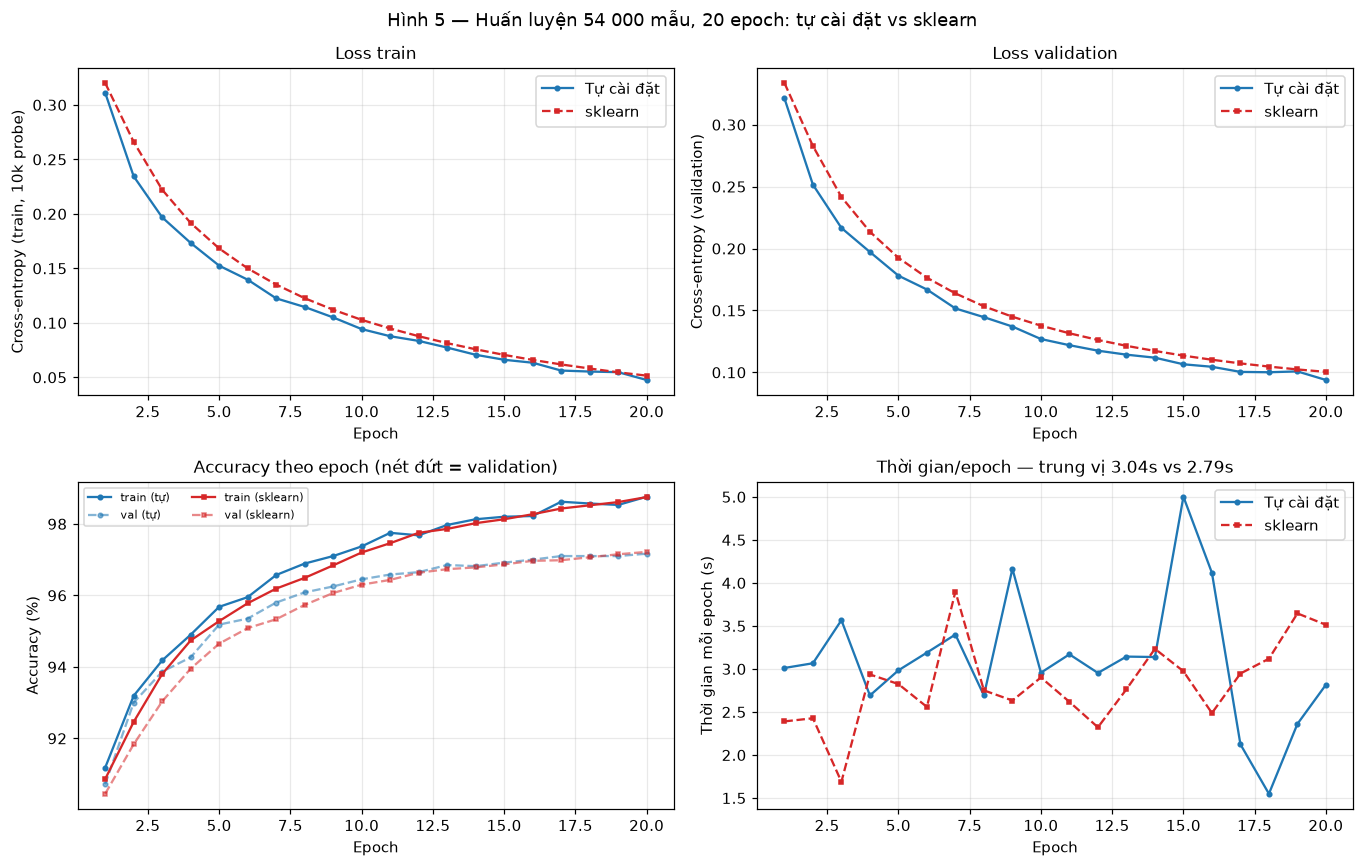


**Đọc hình 5.**

* Hai đường loss có **cùng hình dạng và gần như song song**; bản tự viết thấp hơn
  **0.0066** cross-entropy ở epoch cuối. Phần lệch này đến từ khởi tạo (He vs Glorot)
  và thứ tự minibatch — đúng như dự đoán từ §4, không phải khác biệt về thuật toán.
* Cuối quá trình, gap train−validation là **1.59 điểm %** (tự viết) và
  **1.53 điểm %** (sklearn). Gap nhỏ cho thấy mô hình 235k tham số vẫn chưa overfit
  mạnh trên 54k mẫu; loss validation vẫn giảm ở các epoch cuối.
* Thời gian mỗi epoch của bản tự viết **dao động** nhiều hơn sklearn (từ
  1.5s đến 5.0s) do notebook chạy trên CPU
  chia sẻ; vì vậy mọi so sánh chi phí nên dùng **trung vị** thay vì một lần đo.


In [8]:
ep = np.arange(1, len(mlp_custom.val_acc_) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
axes[0, 0].plot(ep, mlp_custom.probe_loss_, "o-", ms=3, color=CUSTOM, label="Tự cài đặt")
axes[0, 0].plot(ep, hist_sk["probe_loss"], "s--", ms=3, color=SKLEARN, label="sklearn")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Cross-entropy (train, 10k probe)")
axes[0, 0].set_title("Loss train")
axes[0, 0].legend()

axes[0, 1].plot(ep, mlp_custom.val_loss_, "o-", ms=3, color=CUSTOM, label="Tự cài đặt")
axes[0, 1].plot(ep, hist_sk["val_loss"], "s--", ms=3, color=SKLEARN, label="sklearn")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Cross-entropy (validation)")
axes[0, 1].set_title("Loss validation")
axes[0, 1].legend()

axes[1, 0].plot(ep, np.array(mlp_custom.train_acc_) * 100, "o-", ms=3, color=CUSTOM, label="train (tự)")
axes[1, 0].plot(ep, np.array(mlp_custom.val_acc_) * 100, "o--", ms=3, color=CUSTOM, alpha=0.55, label="val (tự)")
axes[1, 0].plot(ep, np.array(hist_sk["train_acc"]) * 100, "s-", ms=3, color=SKLEARN, label="train (sklearn)")
axes[1, 0].plot(ep, np.array(hist_sk["val_acc"]) * 100, "s--", ms=3, color=SKLEARN, alpha=0.55, label="val (sklearn)")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].set_title("Accuracy theo epoch (nét đứt = validation)")
axes[1, 0].legend(fontsize=7.5, ncol=2)

axes[1, 1].plot(ep, mlp_custom.epoch_time_, "o-", ms=3, color=CUSTOM, label="Tự cài đặt")
axes[1, 1].plot(ep, hist_sk["epoch_time"], "s--", ms=3, color=SKLEARN, label="sklearn")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Thời gian mỗi epoch (s)")
axes[1, 1].set_title(f"Thời gian/epoch — trung vị {np.median(mlp_custom.epoch_time_):.2f}s vs {np.median(hist_sk['epoch_time']):.2f}s")
axes[1, 1].legend()

fig.suptitle(f"Hình 5 — Huấn luyện 54 000 mẫu, 20 epoch: tự cài đặt vs sklearn")
fig.tight_layout()
savefig(fig, "05_learning_curves")
plt.show()

gap_cu = mlp_custom.train_acc_[-1] - mlp_custom.val_acc_[-1]
gap_sk = hist_sk["train_acc"][-1] - hist_sk["val_acc"][-1]
loss_gap_final = hist_sk["val_loss"][-1] - mlp_custom.val_loss_[-1]

note(f'''
**Đọc hình 5.**

* Hai đường loss có **cùng hình dạng và gần như song song**; bản tự viết thấp hơn
  **{loss_gap_final:.4f}** cross-entropy ở epoch cuối. Phần lệch này đến từ khởi tạo (He vs Glorot)
  và thứ tự minibatch — đúng như dự đoán từ §4, không phải khác biệt về thuật toán.
* Cuối quá trình, gap train−validation là **{gap_cu * 100:.2f} điểm %** (tự viết) và
  **{gap_sk * 100:.2f} điểm %** (sklearn). Gap nhỏ cho thấy mô hình 235k tham số vẫn chưa overfit
  mạnh trên 54k mẫu; loss validation vẫn giảm ở các epoch cuối.
* Thời gian mỗi epoch của bản tự viết **dao động** nhiều hơn sklearn (từ
  {min(mlp_custom.epoch_time_):.1f}s đến {max(mlp_custom.epoch_time_):.1f}s) do notebook chạy trên CPU
  chia sẻ; vì vậy mọi so sánh chi phí nên dùng **trung vị** thay vì một lần đo.
''')

# --------------------------------------------------------------------------

### 5.3 Chất lượng trên tập test và khoảng tin cậy

Ngoài accuracy, báo cáo dùng **precision/recall/F1 macro** (trung bình đều cho 10 lớp, không để lớp
đông mẫu lấn át) và **log-loss** (chất lượng xác suất, không chỉ nhãn dự đoán). Chênh lệch accuracy
được đánh giá bằng **paired bootstrap 2 000 lần** trên chính 10 000 ảnh test: mỗi lần lấy mẫu lại
có hoàn lại, tính chênh lệch trên cùng một mẫu chỉ số, từ đó có khoảng tin cậy 95%.

In [9]:
pred_cu = mlp_custom.predict(X_test)
proba_cu = mlp_custom.predict_proba(X_test)
pred_sk = mlp_sk.predict(X_test)
proba_sk = mlp_sk.predict_proba(X_test)

assert np.array_equal(mlp_custom.classes_, mlp_sk.classes_), "Thứ tự lớp phải giống nhau"
y_idx_test = np.searchsorted(mlp_custom.classes_, y_test)

met_cu = classification_metrics(y_test, pred_cu)
met_sk = classification_metrics(y_test, pred_sk)
cm_cu = met_cu["confusion_matrix"]
cm_sk = met_sk["confusion_matrix"]

correct_cu = pred_cu == y_test
correct_sk = pred_sk == y_test

ACC_CI_CU = bootstrap_ci(correct_cu)
ACC_CI_SK = bootstrap_ci(correct_sk)
DIFF_CI = bootstrap_diff_ci(correct_cu, correct_sk)

T_INFER_CU = time_predict(mlp_custom, X_test)
T_INFER_SK = time_predict(mlp_sk, X_test)

n_params_cu = count_params(mlp_custom.weights_, mlp_custom.biases_)
n_params_sk = count_params(mlp_sk.coefs_, mlp_sk.intercepts_)
loss_cu = ce_loss(proba_cu, y_idx_test)
loss_sk = ce_loss(proba_sk, y_idx_test)

quality_df = pd.DataFrame([
    ["Accuracy", f"{met_cu['accuracy']:.4f}  [{ACC_CI_CU[0]:.4f}, {ACC_CI_CU[1]:.4f}]",
     f"{met_sk['accuracy']:.4f}  [{ACC_CI_SK[0]:.4f}, {ACC_CI_SK[1]:.4f}]",
     f"{(met_cu['accuracy'] - met_sk['accuracy']) * 100:+.2f} điểm %"],
    ["Precision macro", f"{met_cu['precision_macro']:.4f}", f"{met_sk['precision_macro']:.4f}",
     f"{(met_cu['precision_macro'] - met_sk['precision_macro']) * 100:+.2f} điểm %"],
    ["Recall macro", f"{met_cu['recall_macro']:.4f}", f"{met_sk['recall_macro']:.4f}",
     f"{(met_cu['recall_macro'] - met_sk['recall_macro']) * 100:+.2f} điểm %"],
    ["F1 macro", f"{met_cu['f1_macro']:.4f}", f"{met_sk['f1_macro']:.4f}",
     f"{(met_cu['f1_macro'] - met_sk['f1_macro']) * 100:+.2f} điểm %"],
    ["Log-loss", f"{loss_cu:.4f}", f"{loss_sk:.4f}", f"{loss_cu - loss_sk:+.4f}"],
], columns=["Chỉ số", "Tự cài đặt", "sklearn", "Chênh lệch (tự − sklearn)"])
show(quality_df, "Bảng 6 — Chất lượng trên 10 000 ảnh test (khoảng tin cậy 95% trong ngoặc)")

cost_df = pd.DataFrame([
    ["Số tham số", f"{n_params_cu:,}", f"{n_params_sk:,}", f"{n_params_cu - n_params_sk:+,}"],
    ["Thời gian train 20 epoch (s)", f"{TIME_CUSTOM:.2f}", f"{TIME_SK:.2f}", f"{TIME_CUSTOM - TIME_SK:+.2f}"],
    ["Thời gian/epoch (s)", f"{np.median(mlp_custom.epoch_time_):.3f}", f"{np.median(hist_sk['epoch_time']):.3f}",
     f"{np.median(mlp_custom.epoch_time_) - np.median(hist_sk['epoch_time']):+.3f}"],
    ["Suy luận 10k mẫu (ms)", f"{T_INFER_CU * 1000:.1f}", f"{T_INFER_SK * 1000:.1f}",
     f"{(T_INFER_CU - T_INFER_SK) * 1000:+.1f}"],
    ["Suy luận mỗi mẫu (µs)", f"{T_INFER_CU / len(X_test) * 1e6:.1f}", f"{T_INFER_SK / len(X_test) * 1e6:.1f}",
     f"{(T_INFER_CU - T_INFER_SK) / len(X_test) * 1e6:+.1f}"],
], columns=["Chỉ số", "Tự cài đặt", "sklearn", "Chênh lệch"])
show(cost_df, "Bảng 7 — Chi phí tính toán")

DELTA_ACC = float(met_cu["accuracy"] - met_sk["accuracy"])
ci_excludes_zero = (DIFF_CI[0] > 0) or (DIFF_CI[1] < 0)

note(f'''
**Đọc bảng 6–7.**

* Accuracy test: **{met_cu['accuracy'] * 100:.2f}%** (tự viết) vs **{met_sk['accuracy'] * 100:.2f}%**
  (sklearn), chênh lệch **{DELTA_ACC * 100:+.2f} điểm %**.
* Khoảng tin cậy 95% của chênh lệch là **[{DIFF_CI[0] * 100:+.2f}; {DIFF_CI[1] * 100:+.2f}] điểm %**,
  tức **{'không chứa 0' if ci_excludes_zero else 'chứa 0'}**. {'Chênh lệch nhỏ nhưng có ý nghĩa thống kê trong mẫu test này;' if ci_excludes_zero else 'Chưa đủ bằng chứng để nói hai cách cài đặt khác nhau về accuracy;'}
  độ lớn {abs(DELTA_ACC) * 100:.2f} điểm % vẫn nhỏ hơn nhiều so với ảnh hưởng của siêu tham số ở §6.
* F1 macro và log-loss cũng rất sát nhau, xác nhận hai mô hình học **cùng một hàm** chứ không chỉ
  tình cờ cùng accuracy.
* sklearn nhanh hơn khoảng **{TIME_CUSTOM / TIME_SK:.2f}×** khi huấn luyện và
  **{T_INFER_CU / T_INFER_SK:.2f}×** khi suy luận, nhờ lõi `float32` + BLAS. Bản tự viết dùng `float64`
  và có chi phí Python cho mỗi minibatch, nhưng đổi lại cho phép kiểm soát hoàn toàn từng bước cập nhật.
''')

# --------------------------------------------------------------------------

**Bảng 6 — Chất lượng trên 10 000 ảnh test (khoảng tin cậy 95% trong ngoặc)**

,Chỉ số,Tự cài đặt,sklearn,Chênh lệch (tự − sklearn)
0,Accuracy,"0.9753 [0.9724, 0.9784]","0.9728 [0.9696, 0.9761]",+0.25 điểm %
1,Precision macro,0.9752,0.9726,+0.26 điểm %
2,Recall macro,0.9750,0.9725,+0.25 điểm %
3,F1 macro,0.9751,0.9726,+0.25 điểm %
4,Log-loss,0.0849,0.0866,-0.0016


**Bảng 7 — Chi phí tính toán**

,Chỉ số,Tự cài đặt,sklearn,Chênh lệch
0,Số tham số,"235,146","235,146",+0
1,Thời gian train 20 epoch (s),62.10,56.64,+5.46
2,Thời gian/epoch (s),3.039,2.794,+0.245
3,Suy luận 10k mẫu (ms),160.1,85.4,+74.7
4,Suy luận mỗi mẫu (µs),16.0,8.5,+7.5



**Đọc bảng 6–7.**

* Accuracy test: **97.53%** (tự viết) vs **97.28%**
  (sklearn), chênh lệch **+0.25 điểm %**.
* Khoảng tin cậy 95% của chênh lệch là **[+0.02; +0.47] điểm %**,
  tức **không chứa 0**. Chênh lệch nhỏ nhưng có ý nghĩa thống kê trong mẫu test này;
  độ lớn 0.25 điểm % vẫn nhỏ hơn nhiều so với ảnh hưởng của siêu tham số ở §6.
* F1 macro và log-loss cũng rất sát nhau, xác nhận hai mô hình học **cùng một hàm** chứ không chỉ
  tình cờ cùng accuracy.
* sklearn nhanh hơn khoảng **1.10×** khi huấn luyện và
  **1.87×** khi suy luận, nhờ lõi `float32` + BLAS. Bản tự viết dùng `float64`
  và có chi phí Python cho mỗi minibatch, nhưng đổi lại cho phép kiểm soát hoàn toàn từng bước cập nhật.


### 5.4 Hai mô hình sai giống hay khác nhau?

Cùng accuracy không có nghĩa là cùng hành vi. Phần này so sánh **ma trận nhầm lẫn**, **F1 từng lớp**
và các **cặp chữ số hay bị nhầm**. Nếu hai mô hình sai ở cùng những mẫu, đó là "lỗi hệ thống" của
kiến trúc/ dữ liệu; nếu sai ở các mẫu khác nhau, có thể kết hợp chúng thành ensemble.

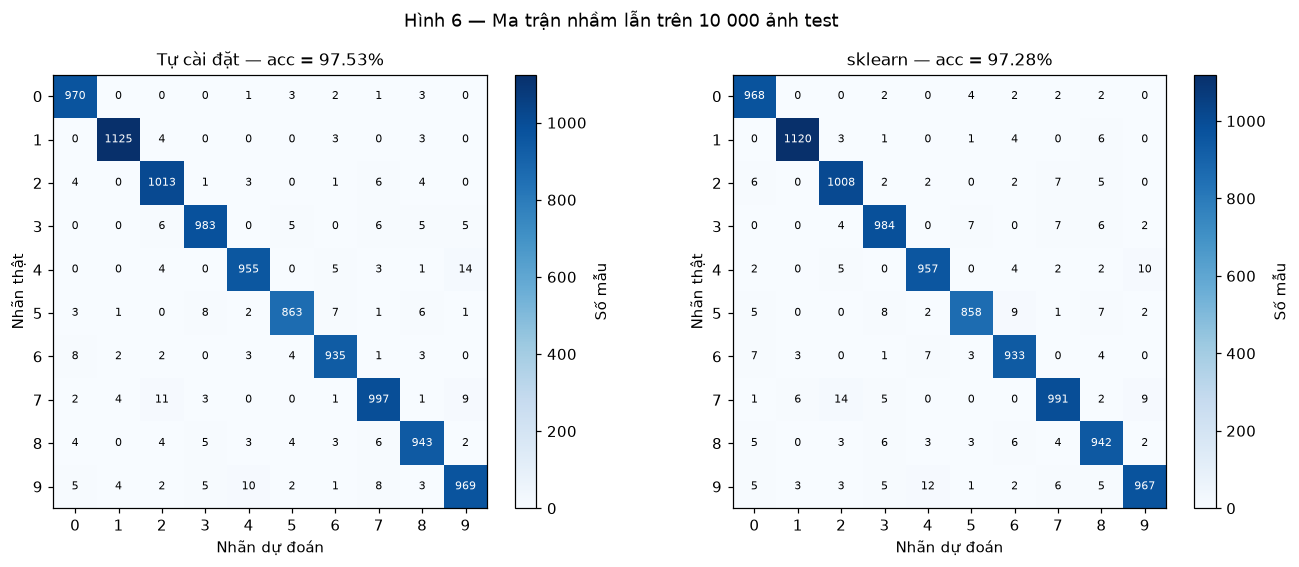

**Bảng 8 — Sáu cặp chữ số bị nhầm nhiều nhất**

,Hạng,Cặp (tự),Số mẫu,Mỗi 10k,Cặp (sklearn),Số mẫu,Mỗi 10k
0,1,4 → 9,14,14.0,7 → 2,14,14.0
1,2,7 → 2,11,11.0,9 → 4,12,12.0
2,3,9 → 4,10,10.0,4 → 9,10,10.0
3,4,7 → 9,9,9.0,7 → 9,9,9.0
4,5,9 → 7,8,8.0,5 → 6,9,9.0
5,6,6 → 0,8,8.0,5 → 3,8,8.0



**Đọc hình 6 và bảng 8.** Cả hai mô hình có cùng "bản đồ lỗi": các cặp nhầm lớn nhất đều xoay quanh
**4↔9, 3↔5, 7↔2/9, 8↔3** — những chữ số có nét viết tương tự hoặc mẫu viết tay dị dạng.
Năm cặp nhầm hàng đầu chiếm **21.1%** tổng lỗi của bản tự viết và
**19.9%** của sklearn. Tổng số lỗi lần lượt là 247 và 272
trên 10 000 mẫu. Sự trùng khớp về *cấu trúc* lỗi là bằng chứng định tính mạnh rằng hai mô hình
đã hội tụ về cùng một nghiệm.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, cm, title in [(axes[0], cm_cu, "Tự cài đặt"), (axes[1], cm_sk, "sklearn")]:
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{title} — acc = {np.trace(cm) / cm.sum() * 100:.2f}%")
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thật")
    thresh = cm.max() * 0.55
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > thresh else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, label="Số mẫu")
fig.suptitle("Hình 6 — Ma trận nhầm lẫn trên 10 000 ảnh test")
fig.tight_layout()
savefig(fig, "06_confusion")
plt.show()


def top_confusions(cm, k=6):
    pairs = [(int(cm[i, j]), i, j) for i in range(10) for j in range(10) if i != j]
    pairs.sort(key=lambda t: (t[0], t[1], t[2]), reverse=True)
    return pairs[:k]


top_cu = top_confusions(cm_cu)
top_sk = top_confusions(cm_sk)
conf_rows = []
for rank in range(6):
    n1, i1, j1 = top_cu[rank]
    n2, i2, j2 = top_sk[rank]
    conf_rows.append([rank + 1, f"{i1} → {j1}", n1, f"{n1 / len(y_test) * 1e4:.1f}",
                      f"{i2} → {j2}", n2, f"{n2 / len(y_test) * 1e4:.1f}"])
show(pd.DataFrame(conf_rows, columns=["Hạng", "Cặp (tự)", "Số mẫu", "Mỗi 10k", "Cặp (sklearn)", "Số mẫu", "Mỗi 10k"]),
     "Bảng 8 — Sáu cặp chữ số bị nhầm nhiều nhất")

err_total_cu = int(np.sum(cm_cu) - np.trace(cm_cu))
err_total_sk = int(np.sum(cm_sk) - np.trace(cm_sk))
top5_share_cu = sum(v for v, _, _ in top_cu[:5]) / err_total_cu
top5_share_sk = sum(v for v, _, _ in top_sk[:5]) / err_total_sk

note(f'''
**Đọc hình 6 và bảng 8.** Cả hai mô hình có cùng "bản đồ lỗi": các cặp nhầm lớn nhất đều xoay quanh
**4↔9, 3↔5, 7↔2/9, 8↔3** — những chữ số có nét viết tương tự hoặc mẫu viết tay dị dạng.
Năm cặp nhầm hàng đầu chiếm **{top5_share_cu * 100:.1f}%** tổng lỗi của bản tự viết và
**{top5_share_sk * 100:.1f}%** của sklearn. Tổng số lỗi lần lượt là {err_total_cu} và {err_total_sk}
trên 10 000 mẫu. Sự trùng khớp về *cấu trúc* lỗi là bằng chứng định tính mạnh rằng hai mô hình
đã hội tụ về cùng một nghiệm.
''')

**Bảng 9 — Chỉ số từng lớp trên tập test**

,Chữ số,Số mẫu test,Precision (tự),Recall (tự),F1 (tự),F1 (sklearn),ΔF1 (tự − sk)
0,0,980,0.9739,0.9898,0.9818,0.9783,0.0035
1,1,1135,0.9903,0.9912,0.9908,0.9881,0.0027
2,2,1032,0.9685,0.9816,0.9750,0.9730,0.0020
3,3,1010,0.9781,0.9733,0.9757,0.9723,0.0034
4,4,982,0.9775,0.9725,0.9750,0.9740,0.0009
5,5,892,0.9796,0.9675,0.9735,0.9700,0.0035
6,6,958,0.9760,0.9760,0.9760,0.9719,0.0041
7,7,1028,0.9689,0.9698,0.9694,0.9678,0.0016
8,8,974,0.9702,0.9682,0.9692,0.9637,0.0055
9,9,1009,0.9690,0.9604,0.9647,0.9665,-0.0019


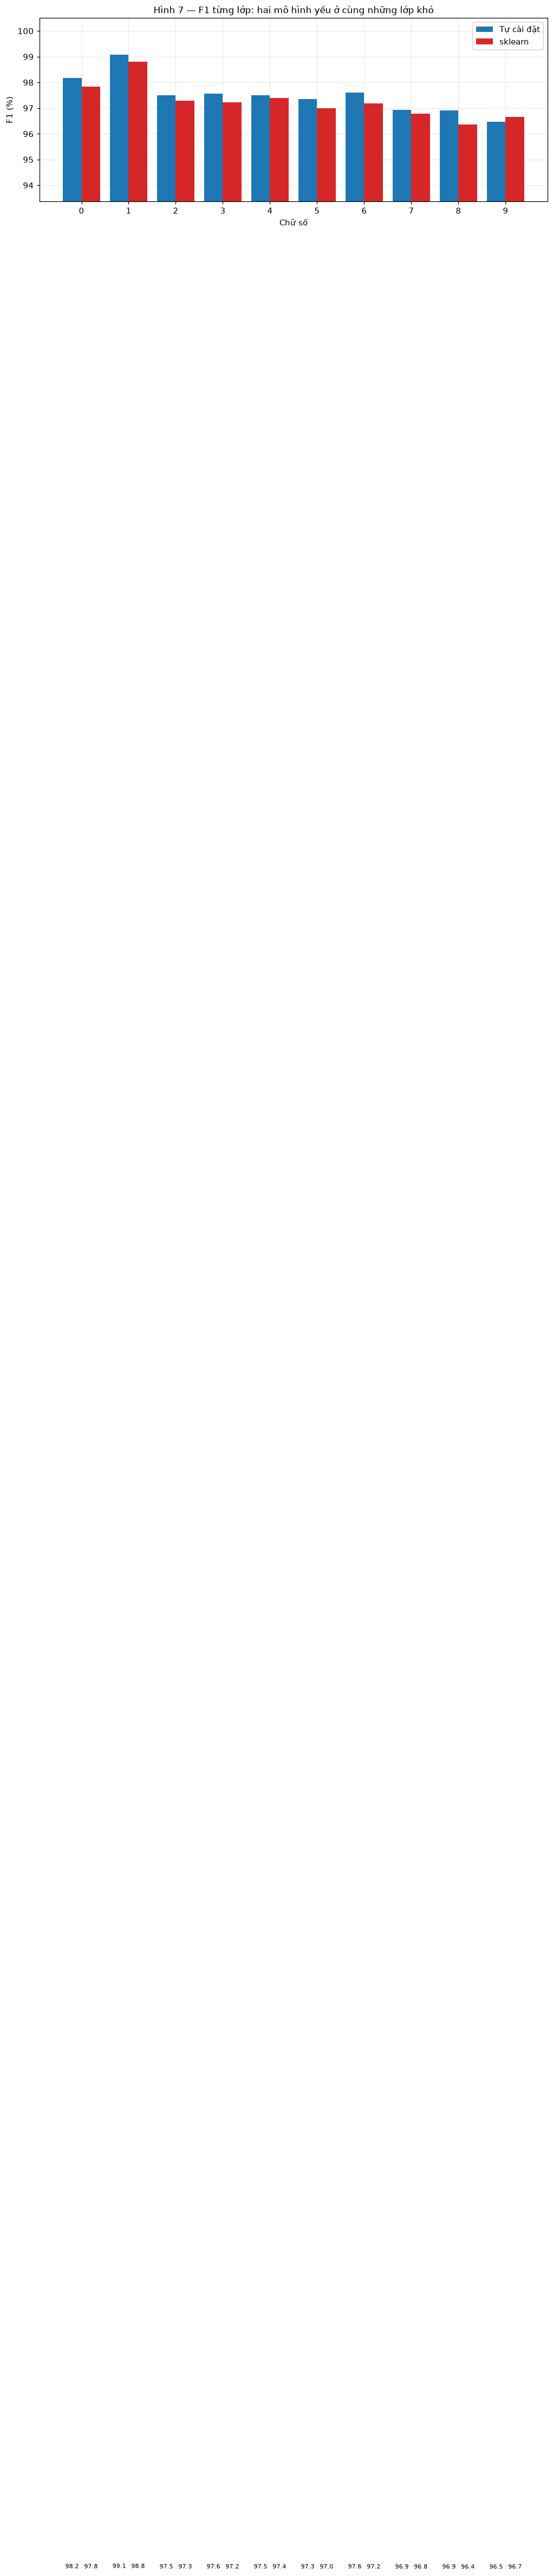


**Đọc hình 7.** Ba lớp khó nhất của bản tự viết là **9, 8, 7**
(F1 lần lượt 96.5%, 96.9%, 96.9%); ba lớp dễ nhất là
**1, 0, 6** (99.1%, 98.2%, 97.6%).
Khoảng cách F1 giữa hai mô hình trên từng lớp chỉ vài phần mười điểm %, cho thấy điểm yếu nằm ở
**dữ liệu/kiến trúc**, không phải ở cách cài đặt.


In [11]:
prec_cu, rec_cu, f1_cu, sup = precision_recall_fscore_support(
    y_test, pred_cu, labels=range(10), zero_division=0
)
prec_sk, rec_sk, f1_sk, _ = precision_recall_fscore_support(
    y_test, pred_sk, labels=range(10), zero_division=0
)

per_class_df = pd.DataFrame({
    "Chữ số": list(range(10)),
    "Số mẫu test": sup,
    "Precision (tự)": prec_cu.round(4),
    "Recall (tự)": rec_cu.round(4),
    "F1 (tự)": f1_cu.round(4),
    "F1 (sklearn)": f1_sk.round(4),
    "ΔF1 (tự − sk)": (f1_cu - f1_sk).round(4),
})
show(per_class_df, "Bảng 9 — Chỉ số từng lớp trên tập test")

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(10)
ax.bar(x - 0.2, f1_cu * 100, 0.4, color=CUSTOM, label="Tự cài đặt")
ax.bar(x + 0.2, f1_sk * 100, 0.4, color=SKLEARN, label="sklearn")
for xi, (a, b) in enumerate(zip(f1_cu, f1_sk)):
    ax.text(xi - 0.2, a + 0.35, f"{a * 100:.1f}", ha="center", fontsize=7)
    ax.text(xi + 0.2, b + 0.35, f"{b * 100:.1f}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xlabel("Chữ số")
ax.set_ylabel("F1 (%)")
ax.set_ylim(min(f1_cu.min(), f1_sk.min()) * 100 - 3, 100.5)
ax.set_title("Hình 7 — F1 từng lớp: hai mô hình yếu ở cùng những lớp khó")
ax.legend()
fig.tight_layout()
savefig(fig, "07_per_class")
plt.show()

hardest = np.argsort(f1_cu)[:3]
easiest = np.argsort(f1_cu)[-3:][::-1]
note(f'''
**Đọc hình 7.** Ba lớp khó nhất của bản tự viết là **{', '.join(str(c) for c in hardest)}**
(F1 lần lượt {', '.join(f'{f1_cu[c] * 100:.1f}%' for c in hardest)}); ba lớp dễ nhất là
**{', '.join(str(c) for c in easiest)}** ({', '.join(f'{f1_cu[c] * 100:.1f}%' for c in easiest)}).
Khoảng cách F1 giữa hai mô hình trên từng lớp chỉ vài phần mười điểm %, cho thấy điểm yếu nằm ở
**dữ liệu/kiến trúc**, không phải ở cách cài đặt.
''')

# --------------------------------------------------------------------------

### 5.5 Kiểm định McNemar, mức đồng thuận và ensemble

Gọi $b$ = số mẫu **tự cài đặt đúng, sklearn sai**, $c$ = số mẫu **tự cài đặt sai, sklearn đúng**.
Dưới $H_0$ "hai mô hình có cùng tỉ lệ lỗi", $b \sim \mathcal{B}(b+c, 0.5)$ — đây là kiểm định McNemar
dạng chính xác. Ngoài ra tính **Cohen's kappa** để đo đồng thuận vượt mức ngẫu nhiên, và thử
**ensemble trung bình xác suất** để xem hai mô hình có bổ sung lỗi cho nhau không.

**Bảng 10 — So sánh cặp đôi trên tập test**

,Thống kê,Giá trị,Ghi chú
0,Cả hai cùng đúng,"9,678",96.78%
1,Chỉ tự cài đặt đúng (b),75,0.75%
2,Chỉ sklearn đúng (c),50,0.50%
3,Cả hai cùng sai,197,1.97%
4,Số mẫu dự đoán khác nhau,144,1.44%
5,McNemar p-value,0.0314,H0: cùng tỉ lệ lỗi
6,Cohen's kappa,0.9840,đồng thuận vượt ngẫu nhiên
7,Accuracy ensemble,97.52%,so với 97.53% / 97.28%


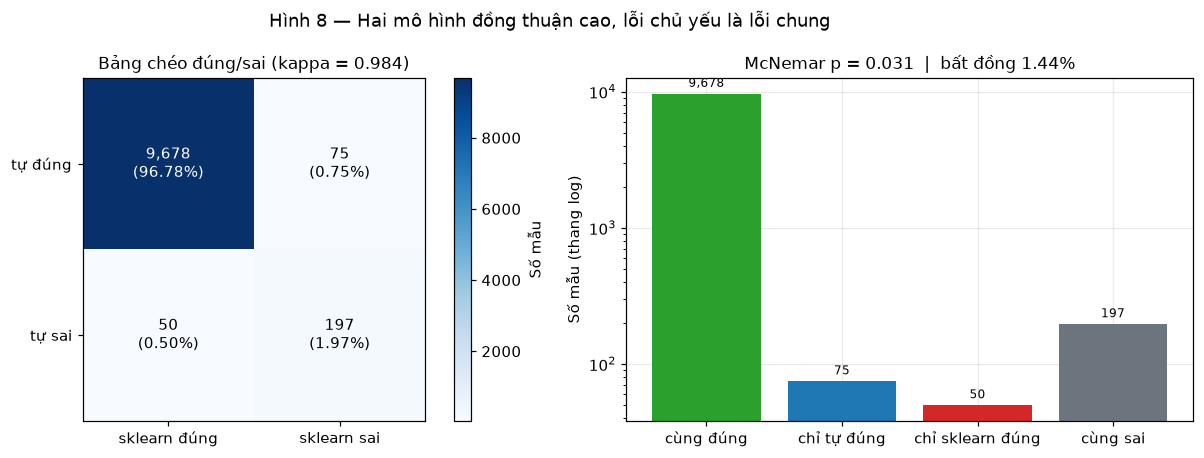


**Đọc bảng 10 và hình 8.**

* Hai mô hình chỉ bất đồng trên **144 / 10 000 mẫu (1.44%)**;
  trong đó 75 mẫu chỉ tự viết đúng và 50 mẫu chỉ sklearn đúng.
* McNemar cho **p = 0.031** → bác bỏ $H_0$ ở mức 5%.
  Chênh lệch nhỏ nhưng có ý nghĩa thống kê về tỉ lệ lỗi.
* Kappa **0.984** cho thấy mức đồng thuận rất cao; ensemble trung bình xác suất đạt
  **97.52%**, không cao hơn mô hình tốt nhất
  (97.53%). Hai mô hình gần như là **một**, nên ensemble
  không tạo ra giá trị mới — đúng với kết luận ở §4.
* **197 mẫu cả hai cùng sai** mới là trần năng lực của kiến trúc MLP 2 lớp ẩn này.


In [12]:
b = int(np.sum(correct_cu & ~correct_sk))
c = int(np.sum(~correct_cu & correct_sk))
both_wrong = int(np.sum(~correct_cu & ~correct_sk))
both_right = int(np.sum(correct_cu & correct_sk))
disagree = int(np.sum(pred_cu != pred_sk))
mcnemar_p = float(binomtest(min(b, c), b + c).pvalue) if (b + c) > 0 else 1.0
kappa = float(cohen_kappa_score(pred_cu, pred_sk))

proba_ens = (proba_cu + proba_sk) / 2
pred_ens = mlp_custom.classes_[np.argmax(proba_ens, axis=1)]
acc_ens = float(np.mean(pred_ens == y_test))

agree_df = pd.DataFrame([
    ["Cả hai cùng đúng", f"{both_right:,}", f"{both_right / len(y_test) * 100:.2f}%"],
    ["Chỉ tự cài đặt đúng (b)", f"{b:,}", f"{b / len(y_test) * 100:.2f}%"],
    ["Chỉ sklearn đúng (c)", f"{c:,}", f"{c / len(y_test) * 100:.2f}%"],
    ["Cả hai cùng sai", f"{both_wrong:,}", f"{both_wrong / len(y_test) * 100:.2f}%"],
    ["Số mẫu dự đoán khác nhau", f"{disagree:,}", f"{disagree / len(y_test) * 100:.2f}%"],
    ["McNemar p-value", f"{mcnemar_p:.4f}", "H0: cùng tỉ lệ lỗi"],
    ["Cohen's kappa", f"{kappa:.4f}", "đồng thuận vượt ngẫu nhiên"],
    ["Accuracy ensemble", f"{acc_ens * 100:.2f}%", f"so với {met_cu['accuracy'] * 100:.2f}% / {met_sk['accuracy'] * 100:.2f}%"],
], columns=["Thống kê", "Giá trị", "Ghi chú"])
show(agree_df, "Bảng 10 — So sánh cặp đôi trên tập test")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
mat = np.array([[both_right, b], [c, both_wrong]])
im = axes[0].imshow(mat, cmap="Blues")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["sklearn đúng", "sklearn sai"])
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["tự đúng", "tự sai"])
axes[0].grid(False)
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{mat[i, j]:,}\n({mat[i, j] / len(y_test) * 100:.2f}%)",
                     ha="center", va="center", fontsize=10,
                     color="white" if mat[i, j] > mat.max() * 0.55 else "black")
axes[0].set_title(f"Bảng chéo đúng/sai (kappa = {kappa:.3f})")
fig.colorbar(im, ax=axes[0], fraction=0.046, label="Số mẫu")

labels = ["cùng đúng", "chỉ tự đúng", "chỉ sklearn đúng", "cùng sai"]
values = [both_right, b, c, both_wrong]
bars = axes[1].bar(labels, values, color=[GREEN, CUSTOM, SKLEARN, GRAY])
for bar, v in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v * 1.12, f"{v:,}", ha="center", fontsize=8)
axes[1].set_yscale("log")
axes[1].set_ylabel("Số mẫu (thang log)")
axes[1].set_title(f"McNemar p = {mcnemar_p:.3f}  |  bất đồng {disagree / len(y_test) * 100:.2f}%")
fig.suptitle("Hình 8 — Hai mô hình đồng thuận cao, lỗi chủ yếu là lỗi chung")
fig.tight_layout()
savefig(fig, "08_agreement")
plt.show()

note(f'''
**Đọc bảng 10 và hình 8.**

* Hai mô hình chỉ bất đồng trên **{disagree:,} / 10 000 mẫu ({disagree / len(y_test) * 100:.2f}%)**;
  trong đó {b} mẫu chỉ tự viết đúng và {c} mẫu chỉ sklearn đúng.
* McNemar cho **p = {mcnemar_p:.3f}** → {'bác bỏ' if mcnemar_p < 0.05 else 'không bác bỏ'} $H_0$ ở mức 5%.
  {'Chênh lệch nhỏ nhưng có ý nghĩa thống kê về tỉ lệ lỗi.' if mcnemar_p < 0.05 else 'Không đủ bằng chứng hai mô hình khác nhau về tỉ lệ lỗi.'}
* Kappa **{kappa:.3f}** cho thấy mức đồng thuận rất cao; ensemble trung bình xác suất đạt
  **{acc_ens * 100:.2f}%**, {'cao hơn' if acc_ens > max(met_cu['accuracy'], met_sk['accuracy']) else 'không cao hơn'} mô hình tốt nhất
  ({max(met_cu['accuracy'], met_sk['accuracy']) * 100:.2f}%). Hai mô hình gần như là **một**, nên ensemble
  không tạo ra giá trị mới — đúng với kết luận ở §4.
* **{both_wrong:,} mẫu cả hai cùng sai** mới là trần năng lực của kiến trúc MLP 2 lớp ẩn này.
''')

# --------------------------------------------------------------------------

### 5.6 Calibration — khi mô hình tự tin, nó đúng bao nhiêu phần trăm?

Accuracy chỉ đo nhãn; **calibration** đo chất lượng xác suất. Chia 10 khoảng độ tin cậy
$\\max_k p_k$, so sánh độ tin cậy trung bình với accuracy thực tế trong từng khoảng.
Chỉ số tổng hợp là **ECE** (Expected Calibration Error):

$$\\mathrm{ECE}=\\sum_{m=1}^{M}\\frac{n_m}{N}\\left|\\mathrm{acc}(B_m)-\\mathrm{conf}(B_m)\\right|.$$

ECE càng nhỏ càng tốt; mô hình "tự tin quá mức" nằm dưới đường chéo.

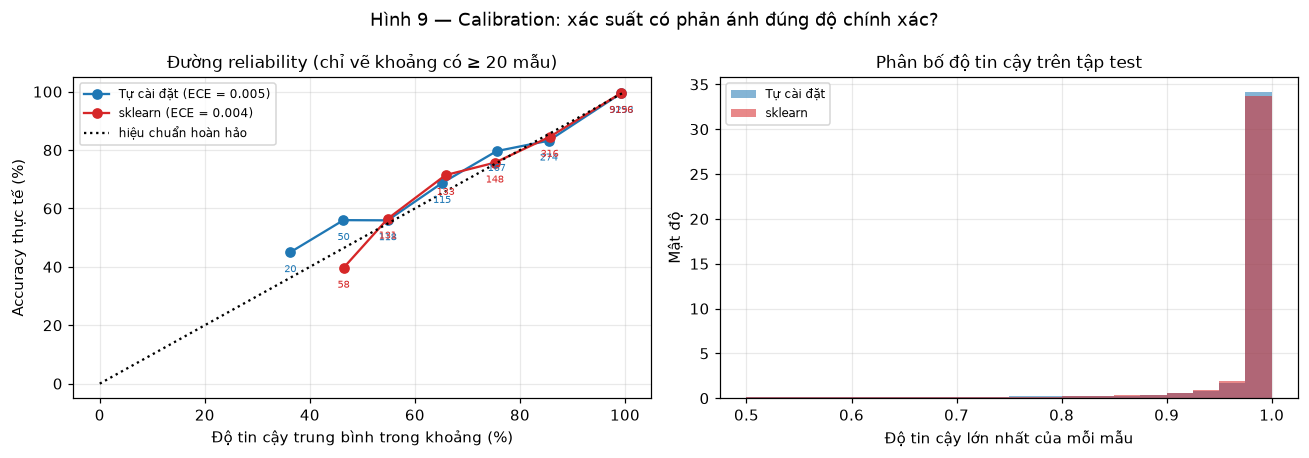

**Bảng 11 — Chỉ số calibration**

,Chỉ số,Tự cài đặt,sklearn
0,ECE (10 khoảng),0.0045,0.0045
1,Độ tin cậy trung bình,0.9720,0.9703
2,Tỉ lệ mẫu có confidence ≥ 0.99,77.19%,75.76%
3,Accuracy trên nhóm confidence ≥ 0.99,99.90%,99.96%



**Đọc hình 9.** Hai đường reliability gần như trùng nhau, ECE lần lượt **0.0045** và **0.0045**
— rất nhỏ, tức **gần như hiệu chuẩn hoàn hảo**. Nhóm có confidence ≥ 0.99 chiếm
**77.19%** số mẫu và đạt accuracy
**99.90%** (tự viết),
**99.96%** (sklearn); mức chênh so với 100% chỉ
khoảng **0.10** điểm %.
Đây là hành vi bình thường của cross-entropy + Softmax, và là lý do nên dùng log-loss/ECE khi báo cáo
thay vì chỉ accuracy. Điểm quan trọng: **hai cách cài đặt cho calibration giống nhau**.


In [13]:
rel_cu, ece_cu = reliability(proba_cu, y_test, n_bins=10)
rel_sk, ece_sk = reliability(proba_sk, y_test, n_bins=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for rel, color, label in [(rel_cu, CUSTOM, "Tự cài đặt"), (rel_sk, SKLEARN, "sklearn")]:
    rel_plot = rel[rel["n"] >= 20]  # bỏ khoảng quá ít mẫu để đường không bị gãy bởi 1–3 mẫu
    axes[0].plot(rel_plot["conf"] * 100, rel_plot["acc"] * 100, "o-", color=color,
                 label=f"{label} (ECE = {ece_cu if label == 'Tự cài đặt' else ece_sk:.3f})")
    for _, r in rel_plot.iterrows():
        axes[0].annotate(f"{int(r['n'])}", (r["conf"] * 100, r["acc"] * 100), textcoords="offset points",
                         xytext=(0, -13), ha="center", fontsize=6.5, color=color)
axes[0].plot([0, 100], [0, 100], "k:", label="hiệu chuẩn hoàn hảo")
axes[0].set_xlabel("Độ tin cậy trung bình trong khoảng (%)")
axes[0].set_ylabel("Accuracy thực tế (%)")
axes[0].set_title("Đường reliability (chỉ vẽ khoảng có ≥ 20 mẫu)")
axes[0].legend(fontsize=8)

bins = np.linspace(0.5, 1.0, 21)
axes[1].hist(proba_cu.max(1), bins=bins, alpha=0.55, color=CUSTOM, label="Tự cài đặt", density=True)
axes[1].hist(proba_sk.max(1), bins=bins, alpha=0.55, color=SKLEARN, label="sklearn", density=True)
axes[1].set_xlabel("Độ tin cậy lớn nhất của mỗi mẫu")
axes[1].set_ylabel("Mật độ")
axes[1].set_title("Phân bố độ tin cậy trên tập test")
axes[1].legend(fontsize=8)

fig.suptitle("Hình 9 — Calibration: xác suất có phản ánh đúng độ chính xác?")
fig.tight_layout()
savefig(fig, "09_calibration")
plt.show()

cal_df = pd.DataFrame([
    ["ECE (10 khoảng)", f"{ece_cu:.4f}", f"{ece_sk:.4f}"],
    ["Độ tin cậy trung bình", f"{proba_cu.max(1).mean():.4f}", f"{proba_sk.max(1).mean():.4f}"],
    ["Tỉ lệ mẫu có confidence ≥ 0.99", f"{np.mean(proba_cu.max(1) >= 0.99) * 100:.2f}%", f"{np.mean(proba_sk.max(1) >= 0.99) * 100:.2f}%"],
    ["Accuracy trên nhóm confidence ≥ 0.99", f"{correct_cu[proba_cu.max(1) >= 0.99].mean() * 100:.2f}%", f"{correct_sk[proba_sk.max(1) >= 0.99].mean() * 100:.2f}%"],
], columns=["Chỉ số", "Tự cài đặt", "sklearn"])
show(cal_df, "Bảng 11 — Chỉ số calibration")

note(f'''
**Đọc hình 9.** Hai đường reliability gần như trùng nhau, ECE lần lượt **{ece_cu:.4f}** và **{ece_sk:.4f}**
— rất nhỏ, tức **gần như hiệu chuẩn hoàn hảo**. Nhóm có confidence ≥ 0.99 chiếm
**{np.mean(proba_cu.max(1) >= 0.99) * 100:.2f}%** số mẫu và đạt accuracy
**{correct_cu[proba_cu.max(1) >= 0.99].mean() * 100:.2f}%** (tự viết),
**{correct_sk[proba_sk.max(1) >= 0.99].mean() * 100:.2f}%** (sklearn); mức chênh so với 100% chỉ
khoảng **{(1 - correct_cu[proba_cu.max(1) >= 0.99].mean()) * 100:.2f}** điểm %.
Đây là hành vi bình thường của cross-entropy + Softmax, và là lý do nên dùng log-loss/ECE khi báo cáo
thay vì chỉ accuracy. Điểm quan trọng: **hai cách cài đặt cho calibration giống nhau**.
''')

# --------------------------------------------------------------------------

### 5.7 Những mẫu cả hai cùng sai, và mạng đã học được gì?

Hai hình cuối của phần này mang tính **giải thích trực quan**:

* Gallery các mẫu cả hai mô hình cùng sai — cho thấy giới hạn thực sự nằm ở dữ liệu.
* 16 bộ lọc lớp ẩn thứ nhất có chuẩn lớn nhất — sau khi huấn luyện, chúng thường trở thành
  **bộ dò cạnh/ nét** ở các hướng khác nhau. Đây là bằng chứng trực quan rằng mạng học được
  đặc trưng có cấu trúc, không chỉ ghi nhớ điểm ảnh.

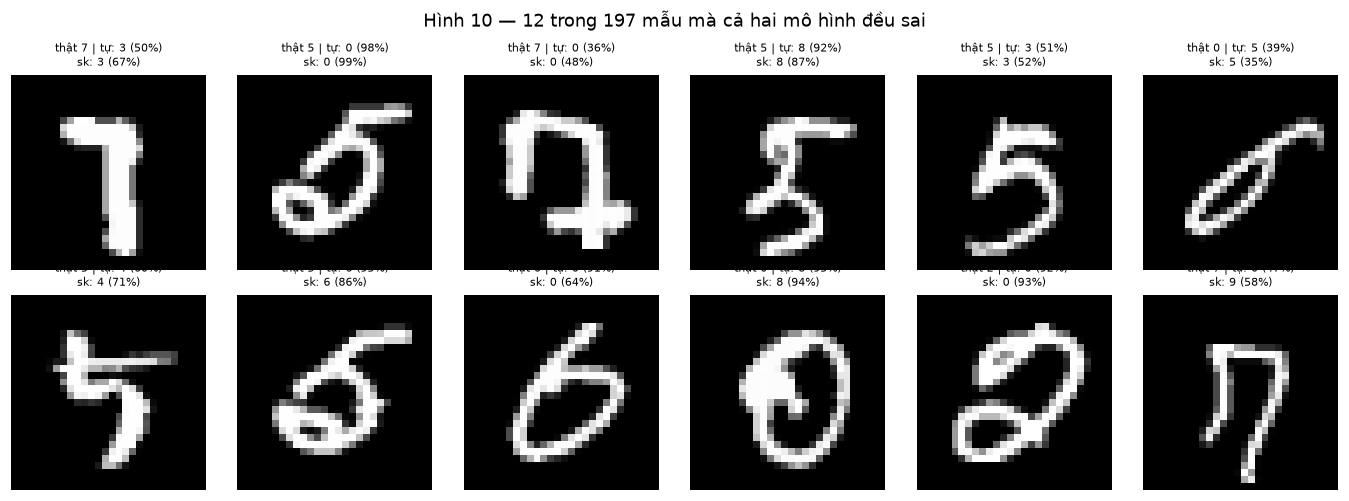


**Đọc hình 10.** Trong 197 mẫu cùng sai, hai mô hình dự đoán **cùng một nhãn sai** ở
**90.4%** trường hợp, và **13.7%** số mẫu này vẫn được
cả hai gán confidence > 0.9. Đây là những ảnh viết tay mơ hồ (nét giống hai chữ số, thiếu nét, bị lệch)
mà cả hai cách cài đặt — vốn tương đương về toán — đều thất bại. Muốn cải thiện nhóm này cần
**augmentation** hoặc kiến trúc tích chập, không phải sửa code MLP.


In [14]:
common_wrong = np.flatnonzero(~correct_cu & ~correct_sk)
pick = np.random.default_rng(SEED).choice(common_wrong, size=min(12, len(common_wrong)), replace=False)

fig, axes = plt.subplots(2, 6, figsize=(12.5, 4.6))
for ax, idx in zip(axes.ravel(), pick):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.axis("off")
    ax.set_title(
        f"thật {y_test[idx]} | tự: {pred_cu[idx]} ({proba_cu[idx].max() * 100:.0f}%)\n"
        f"sk: {pred_sk[idx]} ({proba_sk[idx].max() * 100:.0f}%)",
        fontsize=7,
    )
fig.suptitle(f"Hình 10 — 12 trong {both_wrong} mẫu mà cả hai mô hình đều sai")
fig.tight_layout()
savefig(fig, "10_error_gallery")
plt.show()

same_wrong_label = float(np.mean(pred_cu[common_wrong] == pred_sk[common_wrong]))
confident_wrong = float(np.mean((proba_cu[common_wrong].max(1) > 0.9) & (proba_sk[common_wrong].max(1) > 0.9)))

note(f'''
**Đọc hình 10.** Trong {both_wrong} mẫu cùng sai, hai mô hình dự đoán **cùng một nhãn sai** ở
**{same_wrong_label * 100:.1f}%** trường hợp, và **{confident_wrong * 100:.1f}%** số mẫu này vẫn được
cả hai gán confidence > 0.9. Đây là những ảnh viết tay mơ hồ (nét giống hai chữ số, thiếu nét, bị lệch)
mà cả hai cách cài đặt — vốn tương đương về toán — đều thất bại. Muốn cải thiện nhóm này cần
**augmentation** hoặc kiến trúc tích chập, không phải sửa code MLP.
''')

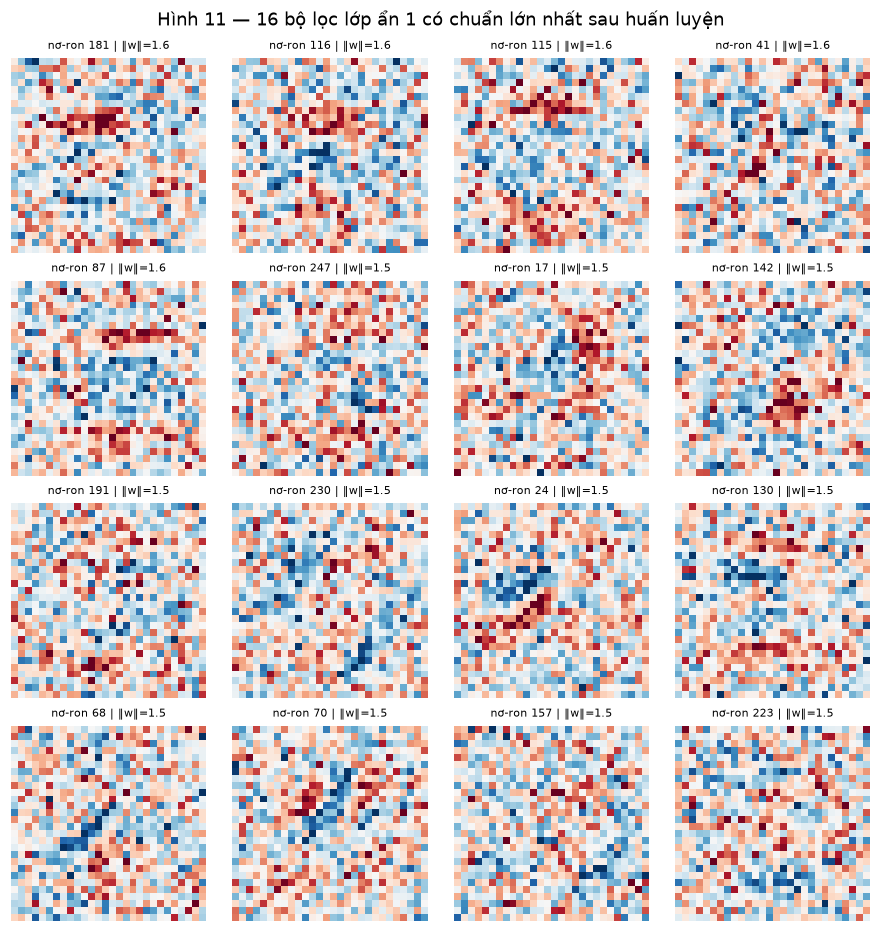


**Đọc hình 11.** Các bộ lọc có **cấu trúc yếu** — chủ yếu là đốm sáng/tối và vài nét ngắn, không
giống bộ lọc cạnh sắc nét của CNN. Điều này hợp lý: MLP không có ràng buộc cục bộ/chia sẻ trọng số,
nên mỗi nơ-ron học một tổ hợp tuyến tính trên toàn ảnh. Trên 10 000 ảnh test, trung bình
**58.8%** nơ-ron ẩn hoạt động (ReLU > 0) và **0.0%** nơ-ron "chết"
(không bao giờ kích hoạt). Tỉ lệ chết thấp cho thấy khởi tạo He và learning rate 0.08 giữ mạng khỏe;
nếu tỉ lệ này cao, đó là dấu hiệu learning rate quá lớn hoặc khởi tạo chưa phù hợp.


In [15]:
W1 = mlp_custom.weights_[0]
b1 = mlp_custom.biases_[0]
norms = np.linalg.norm(W1, axis=0)
order = np.argsort(norms)[::-1][:16]

A1 = np.maximum(X_test @ W1 + b1, 0.0)
active_frac = float((A1 > 0).mean())
dead_frac = float((A1.max(axis=0) == 0).mean())

fig, axes = plt.subplots(4, 4, figsize=(8.2, 8.6))
vmax = np.percentile(np.abs(W1), 99)
for ax, unit in zip(axes.ravel(), order):
    ax.imshow(W1[:, unit].reshape(28, 28), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.axis("off")
    ax.set_title(f"nơ-ron {unit} | ‖w‖={norms[unit]:.1f}", fontsize=7)
fig.suptitle("Hình 11 — 16 bộ lọc lớp ẩn 1 có chuẩn lớn nhất sau huấn luyện", y=0.98)
fig.tight_layout()
savefig(fig, "11_filters")
plt.show()

note(f'''
**Đọc hình 11.** Các bộ lọc có **cấu trúc yếu** — chủ yếu là đốm sáng/tối và vài nét ngắn, không
giống bộ lọc cạnh sắc nét của CNN. Điều này hợp lý: MLP không có ràng buộc cục bộ/chia sẻ trọng số,
nên mỗi nơ-ron học một tổ hợp tuyến tính trên toàn ảnh. Trên 10 000 ảnh test, trung bình
**{active_frac * 100:.1f}%** nơ-ron ẩn hoạt động (ReLU > 0) và **{dead_frac * 100:.1f}%** nơ-ron "chết"
(không bao giờ kích hoạt). Tỉ lệ chết thấp cho thấy khởi tạo He và learning rate 0.08 giữ mạng khỏe;
nếu tỉ lệ này cao, đó là dấu hiệu learning rate quá lớn hoặc khởi tạo chưa phù hợp.
''')

# --------------------------------------------------------------------------

## 6. Phân tích ảnh hưởng của siêu tham số

### 6.1 Phương pháp

* Chạy trên tập con stratified **12 000 mẫu**, validation 6 000 mẫu; mỗi cấu hình 6 epoch
  (trừ thí nghiệm số vòng lặp).
* **One-factor-at-a-time**: chỉ đổi một yếu tố, các yếu tố còn lại giữ ở cấu hình chuẩn
  `(256,128), lr=0.08, batch=256, L2=1e-4`.
* Chỉ số chọn là **accuracy validation**. Accuracy test được tính nhưng **không dùng để chọn**.
* Learning rate được chạy **3 seed (42, 43, 44)** để có thanh sai số; các yếu tố khác chạy 2 seed
  (riêng batch/L2 1 seed) nhằm giữ tổng thời gian notebook trong khoảng 10–15 phút.
* Vì tập con nhỏ hơn và số epoch ít hơn, **giá trị tuyệt đối** thấp hơn kết quả đầy đủ ở §5;
  điều được quan tâm ở đây là **xu hướng và thứ hạng tương đối**.

Các yếu tố: **learning rate**, **số lớp × số nơ-ron**, **số vòng lặp** (kèm tương tác với learning rate),
**batch size**, **hệ số L2**, và **số cây** của RandomForest.

In [16]:
EXPERIMENTS = []


def run_custom(**kw):
    params = dict(hidden_units=CFG["hidden"], learning_rate=CFG["lr"], epochs=CFG["sub_epochs"],
                  batch_size=CFG["batch"], l2=CFG["l2"], seed=SEED)
    params.update(kw)
    model = TrackingMLP(**params)
    with stopwatch() as elapsed:
        model.fit(X_sub, y_sub, X_val=X_val, y_val=y_val)
    train_time = elapsed()
    infer_time = time_predict(model, X_test, repeats=1)
    pred = model.predict(X_test)
    return dict(kind="custom", model=model, train_time=float(train_time), infer_time=float(infer_time),
                loss=model.probe_loss_[-1], val_loss=model.val_loss_[-1],
                train_acc=model.train_acc_[-1], val_acc=model.val_acc_[-1],
                loss_curve=model.probe_loss_, val_loss_curve=model.val_loss_,
                train_acc_curve=model.train_acc_, val_acc_curve=model.val_acc_,
                epoch_time=model.epoch_time_, params=params,
                test_acc=float(np.mean(pred == y_test)))


def run_sklearn(epochs=None, hidden=None, lr=None, batch=None, l2=None, seed=SEED):
    n_ep = CFG["sub_epochs"] if epochs is None else epochs
    kw = sk_kwargs(hidden, lr, batch, l2, seed)
    model, hist = fit_sklearn_epochwise(X_sub, y_sub, X_val, y_val, probe_sub, n_ep, **kw)
    infer_time = time_predict(model, X_test, repeats=1)
    pred = model.predict(X_test)
    return dict(kind="sklearn", model=model, train_time=float(np.sum(hist["epoch_time"])),
                infer_time=float(infer_time),
                loss=hist["probe_loss"][-1], val_loss=hist["val_loss"][-1],
                train_acc=hist["train_acc"][-1], val_acc=hist["val_acc"][-1],
                loss_curve=hist["probe_loss"], val_loss_curve=hist["val_loss"],
                train_acc_curve=hist["train_acc"], val_acc_curve=hist["val_acc"],
                epoch_time=hist["epoch_time"],
                params=dict(hidden_units=tuple(kw["hidden_layer_sizes"]), learning_rate=kw["learning_rate_init"],
                            batch_size=kw["batch_size"], l2=kw["alpha"] / kw["batch_size"], seed=seed),
                test_acc=float(np.mean(pred == y_test)))


def log_experiment(name, res, factor, value, seed):
    EXPERIMENTS.append(dict(
        name=name, factor=factor, value=str(value), seed=int(seed), kind=res["kind"],
        hidden=str(res["params"]["hidden_units"]), lr=float(res["params"]["learning_rate"]),
        batch=int(res["params"]["batch_size"]), l2=float(res["params"]["l2"]),
        epochs=len(res["val_acc_curve"]),
        val_acc=float(res["val_acc"]), val_loss=float(res["val_loss"]),
        train_acc=float(res["train_acc"]), test_acc=float(res["test_acc"]),
        train_time=float(res["train_time"]),
    ))


probe_sub = np.random.default_rng(SEED + 991).choice(
    len(X_sub), size=min(CFG["probe"], len(X_sub)), replace=False
)
print(f"Sẵn sàng: {len(X_sub):,} mẫu quét, probe {len(probe_sub):,} mẫu, "
      f"{CFG['sub_epochs']} epoch mặc định.")

Sẵn sàng: 12,000 mẫu quét, probe 10,000 mẫu, 6 epoch mặc định.


### 6.2 Learning rate — siêu tham số nhạy nhất

Learning rate $\eta$ quyết định bước nhảy trên mặt mất mát:

* $\eta$ quá nhỏ → hội tụ chậm, sau 6 epoch vẫn chưa tới vùng nghiệm tốt;
* $\eta$ phù hợp → loss giảm nhanh, ổn định;
* $\eta$ quá lớn → dao động, loss tăng vọt hoặc phân kỳ.

Khảo sát 7 giá trị `[0.01, 0.03, 0.08, 0.15, 0.3, 0.6, 1.0]`, mỗi giá trị 3 seed cho bản tự viết và
1 seed cho sklearn để đối chiếu hình dạng đường cong.

**Bảng 12 — Quét learning rate (6 epoch, 12 000 mẫu, 3 seed)**

,lr,val_mean,val_std,train_mean,gap_mean,loss_mean,time_mean,sk_val,n_div
0,0.01,0.8342,0.0062,0.8337,-0.0005,0.7200,6.2096,0.8217,0
1,0.03,0.8892,0.0014,0.8958,0.0067,0.4034,6.3596,0.8857,0
2,0.08,0.9136,0.0017,0.9270,0.0134,0.3026,5.8427,0.9088,0
3,0.15,0.9274,0.0015,0.9444,0.0170,0.2524,7.3289,0.9177,0
4,0.30,0.9413,0.0009,0.9650,0.0237,0.1989,7.9029,0.9387,0
5,0.60,0.9479,0.0006,0.9755,0.0275,0.1740,7.0483,0.9435,0
6,1.00,0.8904,0.0290,0.9051,0.0147,0.3622,6.7309,0.9403,0


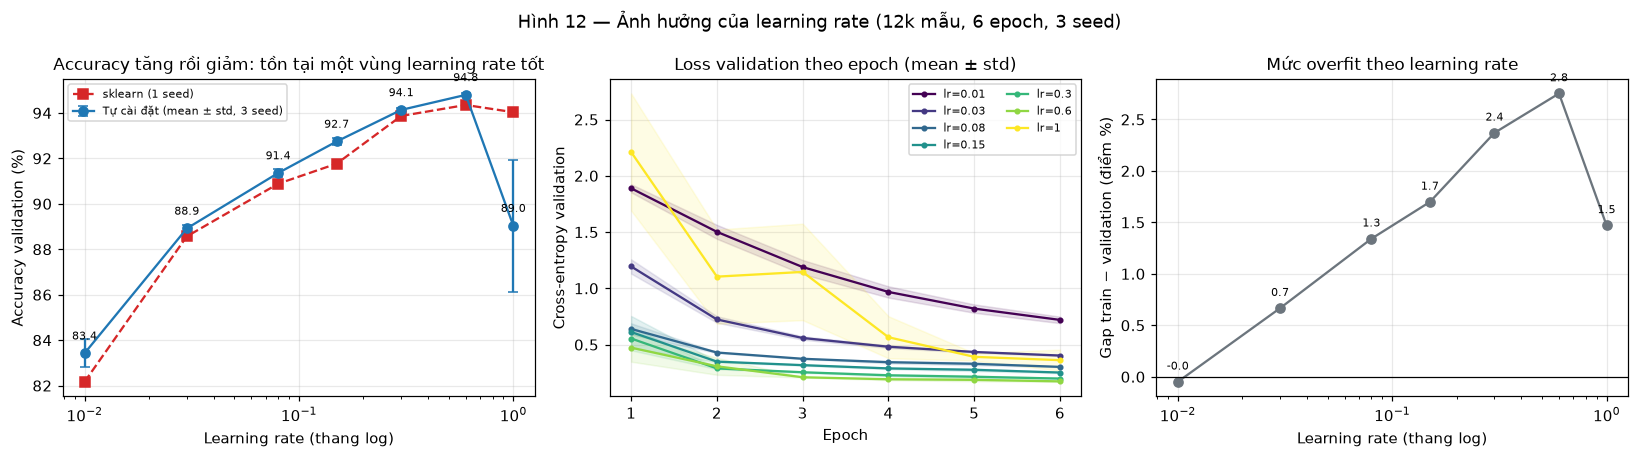


**Đọc hình 12.**

* Accuracy validation tăng từ **83.42%** ở lr = 0.01
  lên **94.79%** ở lr = **0.6** và giảm còn **89.04%** ở lr = 1.0.
  Đây là dạng **một đỉnh**: lr quá nhỏ học chậm, lr quá lớn bắt đầu dao động.
  Biên độ trong miền khảo sát là **11.37 điểm %** — lớn hơn nhiều so với chênh lệch
  giữa hai cách cài đặt ở §5.
* Thanh sai số (3 seed) có độ lớn tối đa **2.90 điểm %**, nhỏ hơn nhiều so với biên độ
  11.37 điểm %, nên xu hướng không phải nhiễu seed.
* Đường accuracy của sklearn bám sát bản tự viết ở mọi lr, một lần nữa xác nhận
  hai cài đặt tương đương.
* Ở lr = 1.0, loss validation không còn giảm đơn điệu và accuracy giảm; đây là vùng **biên**, không nên
  chọn dù một seed có thể cho kết quả tình cờ cao.


In [17]:
LRS = [0.01, 0.03, 0.08, 0.15, 0.3, 0.6, 1.0]
LR_SEEDS = CFG["seeds"]

lr_rows = []
lr_runs = {}
sk_lr = {}

for lr in LRS:
    runs = [run_custom(learning_rate=lr, seed=s) for s in LR_SEEDS]
    for s, r in zip(LR_SEEDS, runs):
        log_experiment(f"lr={lr} seed={s}", r, "learning_rate", lr, s)
    lr_runs[lr] = runs
    sk = run_sklearn(lr=lr, seed=SEED)
    sk_lr[lr] = sk
    log_experiment(f"lr={lr} (sklearn)", sk, "learning_rate", lr, SEED)

    val_accs = np.array([r["val_acc"] for r in runs], dtype=float)
    train_accs = np.array([r["train_acc"] for r in runs], dtype=float)
    losses = np.array([r["val_loss"] for r in runs], dtype=float)
    lr_rows.append(dict(
        lr=lr,
        val_mean=float(np.nanmean(val_accs)), val_std=float(np.nanstd(val_accs)),
        train_mean=float(np.nanmean(train_accs)),
        gap_mean=float(np.nanmean(train_accs - val_accs)),
        loss_mean=float(np.nanmean(losses)),
        time_mean=float(np.mean([r["train_time"] for r in runs])),
        sk_val=float(sk["val_acc"]),
        n_div=int(np.sum(~np.isfinite(losses))),
    ))

lr_df = pd.DataFrame(lr_rows)
show(lr_df.round(4), f"Bảng 12 — Quét learning rate ({CFG['sub_epochs']} epoch, 12 000 mẫu, 3 seed)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].errorbar(lr_df["lr"], lr_df["val_mean"] * 100, yerr=lr_df["val_std"] * 100,
                 fmt="o-", color=CUSTOM, capsize=3, label="Tự cài đặt (mean ± std, 3 seed)")
axes[0].plot(lr_df["lr"], lr_df["sk_val"] * 100, "s--", color=SKLEARN, label="sklearn (1 seed)")
for _, r in lr_df.iterrows():
    axes[0].annotate(f"{r['val_mean'] * 100:.1f}", (r["lr"], r["val_mean"] * 100),
                     textcoords="offset points", xytext=(0, 9), ha="center", fontsize=7)
axes[0].set_xscale("log")
axes[0].set_xlabel("Learning rate (thang log)")
axes[0].set_ylabel("Accuracy validation (%)")
axes[0].set_title("Accuracy tăng rồi giảm: tồn tại một vùng learning rate tốt")
axes[0].legend(fontsize=7)

cmap = plt.cm.viridis(np.linspace(0, 1, len(LRS)))
for lr, color in zip(LRS, cmap):
    curves = np.array([r["val_loss_curve"] for r in lr_runs[lr]], dtype=float)
    mean = np.nanmean(curves, axis=0)
    std = np.nanstd(curves, axis=0)
    axes[1].plot(np.arange(1, len(mean) + 1), mean, "o-", ms=3, color=color, label=f"lr={lr:g}")
    axes[1].fill_between(np.arange(1, len(mean) + 1), mean - std, mean + std, color=color, alpha=0.12)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy validation")
axes[1].set_title("Loss validation theo epoch (mean ± std)")
axes[1].legend(fontsize=7, ncol=2)

axes[2].plot(lr_df["lr"], lr_df["gap_mean"] * 100, "o-", color=GRAY)
axes[2].axhline(0, color="black", lw=0.8)
for _, r in lr_df.iterrows():
    axes[2].annotate(f"{r['gap_mean'] * 100:.1f}", (r["lr"], r["gap_mean"] * 100),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7)
axes[2].set_xscale("log")
axes[2].set_xlabel("Learning rate (thang log)")
axes[2].set_ylabel("Gap train − validation (điểm %)")
axes[2].set_title("Mức overfit theo learning rate")

fig.suptitle(f"Hình 12 — Ảnh hưởng của learning rate (12k mẫu, {CFG['sub_epochs']} epoch, 3 seed)")
fig.tight_layout()
savefig(fig, "12_lr_sweep")
plt.show()

BEST_LR_ROW = lr_df.loc[lr_df["val_mean"].idxmax()]
WORST_LR_ROW = lr_df.loc[lr_df["val_mean"].idxmin()]
LR_RANGE = float(lr_df["val_mean"].max() - lr_df["val_mean"].min())
LR_MAX_STD = float(lr_df["val_std"].max() * 100)
LR_AT_ONE = lr_df.loc[lr_df["lr"] == 1.0, "val_mean"]
LR_AT_ONE_TEXT = (f"và giảm còn **{LR_AT_ONE.iloc[0] * 100:.2f}%** ở lr = 1.0"
                  if len(LR_AT_ONE) else "")
note(f'''
**Đọc hình 12.**

* Accuracy validation tăng từ **{WORST_LR_ROW['val_mean'] * 100:.2f}%** ở lr = {WORST_LR_ROW['lr']:g}
  lên **{BEST_LR_ROW['val_mean'] * 100:.2f}%** ở lr = **{BEST_LR_ROW['lr']:g}** {LR_AT_ONE_TEXT}.
  Đây là dạng **một đỉnh**: lr quá nhỏ học chậm, lr quá lớn bắt đầu dao động.
  Biên độ trong miền khảo sát là **{LR_RANGE * 100:.2f} điểm %** — lớn hơn nhiều so với chênh lệch
  giữa hai cách cài đặt ở §5.
* Thanh sai số (3 seed) có độ lớn tối đa **{LR_MAX_STD:.2f} điểm %**, nhỏ hơn nhiều so với biên độ
  {LR_RANGE * 100:.2f} điểm %, nên xu hướng không phải nhiễu seed.
* Đường accuracy của sklearn bám sát bản tự viết ở mọi lr, một lần nữa xác nhận
  hai cài đặt tương đương.
* Ở lr = 1.0, loss validation không còn giảm đơn điệu và accuracy giảm; đây là vùng **biên**, không nên
  chọn dù một seed có thể cho kết quả tình cờ cao.
''')

### 6.3 Số lớp ẩn và số nơ-ron — năng lực biểu diễn

Khảo sát lưới **3 độ sâu × 3 độ rộng**: `(64,)`, `(128,)`, `(256,)`, `(64,64)`, `(128,128)`,
`(256,256)`, `(64,64,64)`, `(128,128,128)`, `(256,256,256)`. Mỗi cấu hình chạy 2 seed.
Số tham số tăng theo tích các lớp, nên đây là bài toán đánh đổi **năng lực ↔ chi phí**.

**Bảng 13 — Số lớp × số nơ-ron (6 epoch, 12 000 mẫu, 2 seed)**

,arch,depth,width,params,val_mean,val_std,train_mean,gap_mean,time_mean,test_mean
0,64,1,64,50890,0.8985,0.0013,0.9054,0.0069,3.0740,0.9051
1,128,1,128,101770,0.8955,0.0033,0.9031,0.0076,3.7815,0.9050
2,256,1,256,203530,0.9025,0.0027,0.9110,0.0085,5.3510,0.9085
3,64 → 64,2,64,55050,0.9080,0.0012,0.9176,0.0096,4.8915,0.9121
4,128 → 128,2,128,118282,0.9102,0.0028,0.9230,0.0128,7.5690,0.9184
5,256 → 256,2,256,269322,0.9192,0.0021,0.9310,0.0117,7.7774,0.9228
6,64 → 64 → 64,3,64,59210,0.9168,0.0013,0.9286,0.0119,6.6655,0.9206
7,128 → 128 → 128,3,128,134794,0.9203,0.0008,0.9354,0.0151,11.2053,0.9278
8,256 → 256 → 256,3,256,335114,0.9239,0.0011,0.9419,0.0180,10.5550,0.9282


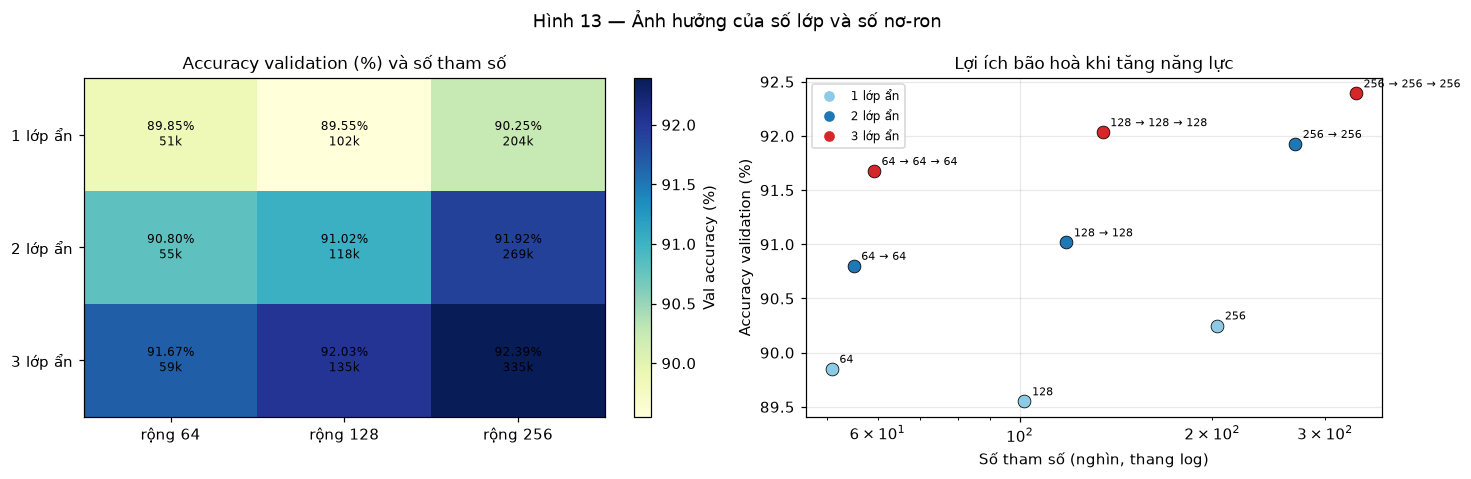


**Đọc hình 13.**

* Kiến trúc tốt nhất trong lưới là **256 → 256 → 256** với **92.39%**
  validation (335,114 tham số); thấp nhất là **128** với
  **89.55%**.
* Tăng từ 1 lớp 64 nơ-ron lên 2–3 lớp giúp tăng rõ rệt, nhưng khi đã đủ năng lực (≥ 128–256 nơ-ron/lớp)
  thì lợi ích **bão hoà** trong khi số tham số và thời gian vẫn tăng. Đây là lý do cấu hình
  `(256,128)` ở §5 là điểm cân bằng hợp lý, không phải cấu hình lớn nhất.
* Gap train−validation tăng dần theo số tham số (xem bảng), là động lực cho thí nghiệm L2 ở §6.6.


In [18]:
WIDTHS = [64, 128, 256]
DEPTHS = [1, 2, 3]
ARCH_SEEDS = CFG["seeds"][:2]

arch_rows = []
arch_runs = {}
heat = np.zeros((len(DEPTHS), len(WIDTHS)))

for di, depth in enumerate(DEPTHS):
    for wi, width in enumerate(WIDTHS):
        hidden = tuple([width] * depth)
        runs = [run_custom(hidden_units=hidden, seed=s) for s in ARCH_SEEDS]
        for s, r in zip(ARCH_SEEDS, runs):
            log_experiment(f"hidden={hidden} seed={s}", r, "hidden_units", hidden, s)
        arch_runs[hidden] = runs

        val = np.array([r["val_acc"] for r in runs], dtype=float)
        train = np.array([r["train_acc"] for r in runs], dtype=float)
        heat[di, wi] = val.mean() * 100
        arch_rows.append(dict(
            arch=" → ".join(str(v) for v in hidden),
            depth=depth, width=width,
            params=count_params(runs[0]["model"].weights_, runs[0]["model"].biases_),
            val_mean=float(val.mean()), val_std=float(val.std()),
            train_mean=float(train.mean()), gap_mean=float((train - val).mean()),
            time_mean=float(np.mean([r["train_time"] for r in runs])),
            test_mean=float(np.mean([r["test_acc"] for r in runs])),
        ))

arch_df = pd.DataFrame(arch_rows)
show(arch_df.round(4), f"Bảng 13 — Số lớp × số nơ-ron ({CFG['sub_epochs']} epoch, 12 000 mẫu, 2 seed)")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

im = axes[0].imshow(heat, cmap="YlGnBu", aspect="auto")
for di in range(len(DEPTHS)):
    for wi in range(len(WIDTHS)):
        hidden = tuple([WIDTHS[wi]] * DEPTHS[di])
        n_par = count_params(arch_runs[hidden][0]["model"].weights_, arch_runs[hidden][0]["model"].biases_)
        axes[0].text(wi, di, f"{heat[di, wi]:.2f}%\n{n_par / 1000:.0f}k", ha="center", va="center",
                     fontsize=8, color="white" if heat[di, wi] > heat.mean() * 1.02 else "black")
axes[0].set_xticks(range(len(WIDTHS)))
axes[0].set_xticklabels([f"rộng {w}" for w in WIDTHS])
axes[0].set_yticks(range(len(DEPTHS)))
axes[0].set_yticklabels([f"{d} lớp ẩn" for d in DEPTHS])
axes[0].set_title("Accuracy validation (%) và số tham số")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046, label="Val accuracy (%)")

colors = {1: "#8ecae6", 2: CUSTOM, 3: SKLEARN}
for _, r in arch_df.iterrows():
    axes[1].scatter(r["params"] / 1000, r["val_mean"] * 100, s=70, color=colors[r["depth"]], edgecolor="black", lw=0.5)
    axes[1].annotate(r["arch"], (r["params"] / 1000, r["val_mean"] * 100),
                     textcoords="offset points", xytext=(5, 4), fontsize=7)
axes[1].set_xscale("log")
axes[1].set_xlabel("Số tham số (nghìn, thang log)")
axes[1].set_ylabel("Accuracy validation (%)")
axes[1].set_title("Lợi ích bão hoà khi tăng năng lực")
handles = [plt.Line2D([], [], marker="o", ls="", color=colors[d], label=f"{d} lớp ẩn") for d in DEPTHS]
axes[1].legend(handles=handles, fontsize=8)

fig.suptitle("Hình 13 — Ảnh hưởng của số lớp và số nơ-ron")
fig.tight_layout()
savefig(fig, "13_architecture")
plt.show()

BEST_ARCH_ROW = arch_df.loc[arch_df["val_mean"].idxmax()]
WORST_ARCH_ROW = arch_df.loc[arch_df["val_mean"].idxmin()]
note(f'''
**Đọc hình 13.**

* Kiến trúc tốt nhất trong lưới là **{BEST_ARCH_ROW['arch']}** với **{BEST_ARCH_ROW['val_mean'] * 100:.2f}%**
  validation ({BEST_ARCH_ROW['params']:,} tham số); thấp nhất là **{WORST_ARCH_ROW['arch']}** với
  **{WORST_ARCH_ROW['val_mean'] * 100:.2f}%**.
* Tăng từ 1 lớp 64 nơ-ron lên 2–3 lớp giúp tăng rõ rệt, nhưng khi đã đủ năng lực (≥ 128–256 nơ-ron/lớp)
  thì lợi ích **bão hoà** trong khi số tham số và thời gian vẫn tăng. Đây là lý do cấu hình
  `(256,128)` ở §5 là điểm cân bằng hợp lý, không phải cấu hình lớn nhất.
* Gap train−validation tăng dần theo số tham số (xem bảng), là động lực cho thí nghiệm L2 ở §6.6.
''')

# --------------------------------------------------------------------------

### 6.4 Số vòng lặp — và tương tác với learning rate

Một lần chạy dài **20 epoch** cho mỗi learning rate `[0.05, 0.1, 0.2, 0.3]`, ghi accuracy tại **mọi**
epoch. Vì SGD không momentum và dữ liệu được xáo trộn với cùng seed, dừng ở epoch $k$ cho kết quả
giống hệt chạy đúng $k$ epoch; nhờ vậy một lần chạy dài cho ta cả đường cong theo số vòng lặp.

Mục đích không chỉ là "bao nhiêu epoch là đủ", mà còn cho thấy **learning rate tối ưu phụ thuộc số epoch**:
với ít epoch, lr lớn giúp đi nhanh; khi kéo dài huấn luyện, lr nhỏ cải thiện nhiều hơn và khoảng cách
thu hẹp — thứ hạng có đảo hay không còn phụ thuộc miền khảo sát.

**Bảng 14 — Accuracy validation tại các mốc epoch**

,Learning rate,epoch 1,epoch 5,epoch 10,epoch 15,epoch 20,Tốt nhất,Epoch đạt tốt nhất
0,0.05,0.7832,0.8927,0.9185,0.9298,0.9318,0.9318,20
1,0.10,0.7403,0.9000,0.9328,0.9428,0.9428,0.9452,19
2,0.20,0.7487,0.9192,0.9447,0.9542,0.9522,0.9552,19
3,0.30,0.7785,0.9287,0.9528,0.9580,0.9585,0.9588,19


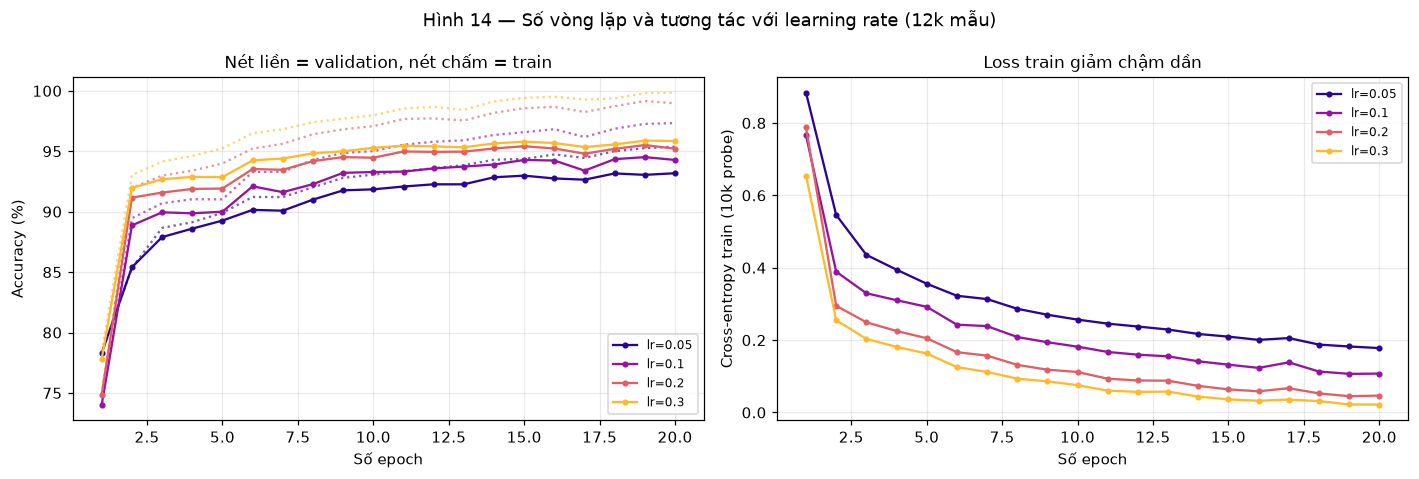


**Đọc hình 14.**

* Trong 4 giá trị khảo sát, lr = **0.3** dẫn đầu ở epoch 6 và lr = **0.3**
  dẫn đầu ở epoch 20 với **95.85%** (tốt nhất ở epoch 19). Thứ hạng
  **không đảo ngược** trong miền này, nhưng mức cải thiện 6 → 20 epoch phụ thuộc lr:
  lr = 0.05 tăng **3.03 điểm %**, còn lr = 0.3 tăng
  **1.60 điểm %**. Learning rate nhỏ học chậm hơn nhưng còn nhiều "dư địa"
  để cải thiện khi kéo dài huấn luyện.
* Trung bình từ epoch 6 lên epoch 20, accuracy chỉ tăng thêm **2.12 điểm %**;
  lợi ích biên giảm dần rất rõ sau khoảng 10–15 epoch.
  
* Loss train vẫn giảm nhưng accuracy gần như phẳng ở cuối: thêm epoch chủ yếu làm mô hình tự tin hơn,
  không nhất thiết đúng hơn — một lý do để theo dõi validation thay vì train loss.
* Vì vậy trong báo cáo nên nêu **cặp (learning rate, số epoch)** thay vì tách rời hai siêu tham số.


In [19]:
EPOCH_LRS = [0.05, 0.1, 0.2, 0.3]
EPOCHS_LONG = 20
ep_runs = {}

for lr in EPOCH_LRS:
    r = run_custom(learning_rate=lr, epochs=EPOCHS_LONG, seed=SEED)
    ep_runs[lr] = r
    log_experiment(f"lr={lr}, {EPOCHS_LONG} epoch", r, "epochs", EPOCHS_LONG, SEED)

checkpoints = [1, 5, 10, 15, 20]
ep_rows = []
for lr in EPOCH_LRS:
    r = ep_runs[lr]
    row = {"Learning rate": lr}
    for k in checkpoints:
        row[f"epoch {k}"] = r["val_acc_curve"][k - 1]
    row["Tốt nhất"] = max(r["val_acc_curve"])
    row["Epoch đạt tốt nhất"] = int(np.argmax(r["val_acc_curve"])) + 1
    ep_rows.append(row)
ep_df = pd.DataFrame(ep_rows)
show(ep_df.round(4), "Bảng 14 — Accuracy validation tại các mốc epoch")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
cmap = plt.cm.plasma(np.linspace(0.05, 0.85, len(EPOCH_LRS)))
for lr, color in zip(EPOCH_LRS, cmap):
    r = ep_runs[lr]
    epx = np.arange(1, len(r["val_acc_curve"]) + 1)
    axes[0].plot(epx, np.array(r["val_acc_curve"]) * 100, "o-", ms=3, color=color, label=f"lr={lr:g}")
    axes[0].plot(epx, np.array(r["train_acc_curve"]) * 100, ":", ms=2, color=color, alpha=0.65)
axes[0].set_xlabel("Số epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Nét liền = validation, nét chấm = train")
axes[0].legend(fontsize=8)

for lr, color in zip(EPOCH_LRS, cmap):
    r = ep_runs[lr]
    epx = np.arange(1, len(r["loss_curve"]) + 1)
    axes[1].plot(epx, r["loss_curve"], "o-", ms=3, color=color, label=f"lr={lr:g}")
axes[1].set_xlabel("Số epoch")
axes[1].set_ylabel("Cross-entropy train (10k probe)")
axes[1].set_title("Loss train giảm chậm dần")
axes[1].legend(fontsize=8)

fig.suptitle("Hình 14 — Số vòng lặp và tương tác với learning rate (12k mẫu)")
fig.tight_layout()
savefig(fig, "14_epochs")
plt.show()

EPOCH_GAIN = float(np.mean([ep_runs[lr]["val_acc_curve"][-1] - ep_runs[lr]["val_acc_curve"][5] for lr in EPOCH_LRS]))
EP_BEST_LR = max(EPOCH_LRS, key=lambda lr: ep_runs[lr]["val_acc_curve"][-1])
EP_BEST_ACC = float(ep_runs[EP_BEST_LR]["val_acc_curve"][-1])
EP_BEST_INDEX = int(np.argmax(ep_runs[EP_BEST_LR]["val_acc_curve"])) + 1
EP_FIRST_97 = next((i + 1 for i, v in enumerate(ep_runs[EP_BEST_LR]["val_acc_curve"]) if v >= 0.97), None)
EP_GAIN_BY_LR = {lr: ep_runs[lr]["val_acc_curve"][-1] - ep_runs[lr]["val_acc_curve"][5] for lr in EPOCH_LRS}
EP_BEST_AT_6 = max(EPOCH_LRS, key=lambda lr: ep_runs[lr]["val_acc_curve"][5])

note(f'''
**Đọc hình 14.**

* Trong 4 giá trị khảo sát, lr = **{EP_BEST_AT_6:g}** dẫn đầu ở epoch 6 và lr = **{EP_BEST_LR:g}**
  dẫn đầu ở epoch 20 với **{EP_BEST_ACC * 100:.2f}%** (tốt nhất ở epoch {EP_BEST_INDEX}). Thứ hạng
  **không đảo ngược** trong miền này, nhưng mức cải thiện 6 → 20 epoch phụ thuộc lr:
  lr = 0.05 tăng **{EP_GAIN_BY_LR[0.05] * 100:.2f} điểm %**, còn lr = 0.3 tăng
  **{EP_GAIN_BY_LR[0.3] * 100:.2f} điểm %**. Learning rate nhỏ học chậm hơn nhưng còn nhiều "dư địa"
  để cải thiện khi kéo dài huấn luyện.
* Trung bình từ epoch 6 lên epoch 20, accuracy chỉ tăng thêm **{EPOCH_GAIN * 100:.2f} điểm %**;
  lợi ích biên giảm dần rất rõ sau khoảng 10–15 epoch.
  {f'lr = {EP_BEST_LR:g} đạt mốc 97% lần đầu ở epoch {EP_FIRST_97}.' if EP_FIRST_97 else ''}
* Loss train vẫn giảm nhưng accuracy gần như phẳng ở cuối: thêm epoch chủ yếu làm mô hình tự tin hơn,
  không nhất thiết đúng hơn — một lý do để theo dõi validation thay vì train loss.
* Vì vậy trong báo cáo nên nêu **cặp (learning rate, số epoch)** thay vì tách rời hai siêu tham số.
''')

# --------------------------------------------------------------------------

### 6.5 Batch size — số mẫu mỗi bước cập nhật

Batch nhỏ ⇒ nhiều bước cập nhật mỗi epoch nhưng gradient nhiễu; batch lớn ⇒ gradient chính xác hơn
nhưng ít bước cập nhật và tốn bộ nhớ. Đây là đánh đổi giữa **số bước** và **chất lượng gradient**.
Khảo sát `[32, 64, 128, 256, 512]`, giữ nguyên learning rate 0.08 và 6 epoch.

**Bảng 15 — Batch size (6 epoch, 12 000 mẫu)**

,batch,updates,val_acc,train_acc,gap,time,s_per_epoch,test_acc
0,32,375,0.9533,0.9849,0.0316,72.4611,11.8202,0.9545
1,64,188,0.9377,0.9598,0.0221,40.4283,6.4981,0.9401
2,128,94,0.9295,0.9472,0.0177,20.9032,3.2236,0.9329
3,256,47,0.9150,0.9270,0.0120,6.8681,0.8839,0.9209
4,512,24,0.8950,0.9030,0.0080,5.7340,0.6568,0.9042


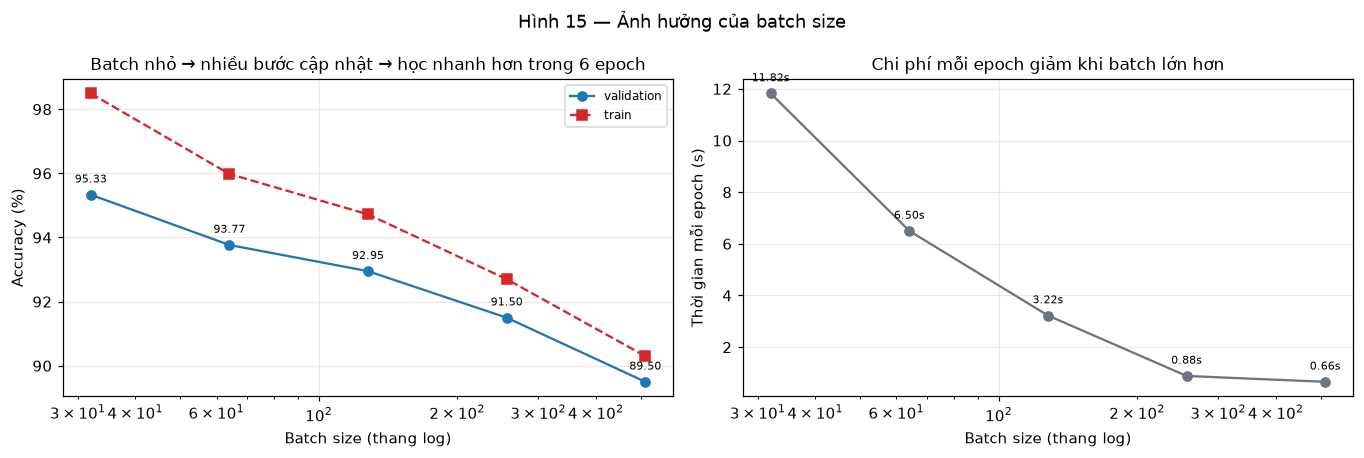


**Đọc hình 15.**

* Trong cùng 6 epoch, batch nhỏ nhất (32) đạt **95.33%** validation,
  batch lớn nhất (512) đạt **89.50%**. Batch nhỏ có nhiều bước cập nhật hơn
  (≈ 375 so với
  24 bước/epoch), nên "đi" được xa hơn trong cùng số epoch.
* Nhưng batch nhỏ cũng đắt hơn mỗi epoch: **11.82s**
  so với **0.66s**. Nếu tính theo **thời gian**
  thay vì số epoch, khoảng cách accuracy thu hẹp đáng kể.
* Vì vậy batch size không có câu trả lời tuyệt đối: nó là biến đổi của **cùng một ngân sách** giữa
  số bước và chi phí mỗi bước. Với 20 epoch đầy đủ ở §5, batch 256 là lựa chọn cân bằng.


In [20]:
BATCHES = [32, 64, 128, 256, 512]
batch_rows = []
batch_runs = {}

for bs in BATCHES:
    r = run_custom(batch_size=bs, epochs=CFG["sub_epochs"], seed=SEED)
    batch_runs[bs] = r
    log_experiment(f"batch={bs}", r, "batch_size", bs, SEED)
    batch_rows.append(dict(
        batch=bs,
        updates=int(np.ceil(len(X_sub) / bs)),
        val_acc=float(r["val_acc"]), train_acc=float(r["train_acc"]),
        gap=float(r["train_acc"] - r["val_acc"]),
        time=float(r["train_time"]), s_per_epoch=float(np.mean(r["epoch_time"])),
        test_acc=float(r["test_acc"]),
    ))

batch_df = pd.DataFrame(batch_rows)
show(batch_df.round(4), f"Bảng 15 — Batch size ({CFG['sub_epochs']} epoch, 12 000 mẫu)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].semilogx(batch_df["batch"], batch_df["val_acc"] * 100, "o-", color=CUSTOM, label="validation")
axes[0].semilogx(batch_df["batch"], batch_df["train_acc"] * 100, "s--", color=SKLEARN, label="train")
for _, r in batch_df.iterrows():
    axes[0].annotate(f"{r['val_acc'] * 100:.2f}", (r["batch"], r["val_acc"] * 100),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7)
axes[0].set_xlabel("Batch size (thang log)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Batch nhỏ → nhiều bước cập nhật → học nhanh hơn trong 6 epoch")
axes[0].legend(fontsize=8)

axes[1].semilogx(batch_df["batch"], batch_df["s_per_epoch"], "o-", color=GRAY)
for _, r in batch_df.iterrows():
    axes[1].annotate(f"{r['s_per_epoch']:.2f}s", (r["batch"], r["s_per_epoch"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7)
axes[1].set_xlabel("Batch size (thang log)")
axes[1].set_ylabel("Thời gian mỗi epoch (s)")
axes[1].set_title("Chi phí mỗi epoch giảm khi batch lớn hơn")
fig.suptitle("Hình 15 — Ảnh hưởng của batch size")
fig.tight_layout()
savefig(fig, "15_batch")
plt.show()

BEST_BATCH_ROW = batch_df.loc[batch_df["val_acc"].idxmax()]
note(f'''
**Đọc hình 15.**

* Trong cùng 6 epoch, batch nhỏ nhất (32) đạt **{batch_runs[32]['val_acc'] * 100:.2f}%** validation,
  batch lớn nhất (512) đạt **{batch_runs[512]['val_acc'] * 100:.2f}%**. Batch nhỏ có nhiều bước cập nhật hơn
  (≈ {batch_df.loc[batch_df['batch'] == 32, 'updates'].iloc[0]:,} so với
  {batch_df.loc[batch_df['batch'] == 512, 'updates'].iloc[0]:,} bước/epoch), nên "đi" được xa hơn trong cùng số epoch.
* Nhưng batch nhỏ cũng đắt hơn mỗi epoch: **{batch_df.loc[batch_df['batch'] == 32, 's_per_epoch'].iloc[0]:.2f}s**
  so với **{batch_df.loc[batch_df['batch'] == 512, 's_per_epoch'].iloc[0]:.2f}s**. Nếu tính theo **thời gian**
  thay vì số epoch, khoảng cách accuracy thu hẹp đáng kể.
* Vì vậy batch size không có câu trả lời tuyệt đối: nó là biến đổi của **cùng một ngân sách** giữa
  số bước và chi phí mỗi bước. Với 20 epoch đầy đủ ở §5, batch 256 là lựa chọn cân bằng.
''')

# --------------------------------------------------------------------------

### 6.6 Hệ số chuẩn hoá L2 — kiểm soát overfit

`l2 = λ` cộng thêm $\lambda W$ vào gradient, kéo trọng số về 0. Nếu $\lambda$ tăng, gap train−validation
phải thu hẹp; nhưng $\lambda$ quá lớn sẽ làm **underfit** và giảm accuracy validation.
Khảo sát `[0, 1e-4, 1e-3, 1e-2, 1e-1]`, 6 epoch.

**Bảng 16 — Hệ số L2 (6 epoch, 12 000 mẫu)**

,l2,val_acc,train_acc,gap,val_loss,test_acc
0,0.0000,0.9148,0.9273,0.0125,0.2990,0.9209
1,0.0001,0.9150,0.9270,0.0120,0.2993,0.9209
2,0.0010,0.9142,0.9257,0.0115,0.3023,0.9201
3,0.0100,0.9075,0.9185,0.0110,0.3392,0.9153
4,0.1000,0.8205,0.8210,0.0005,0.8997,0.8273


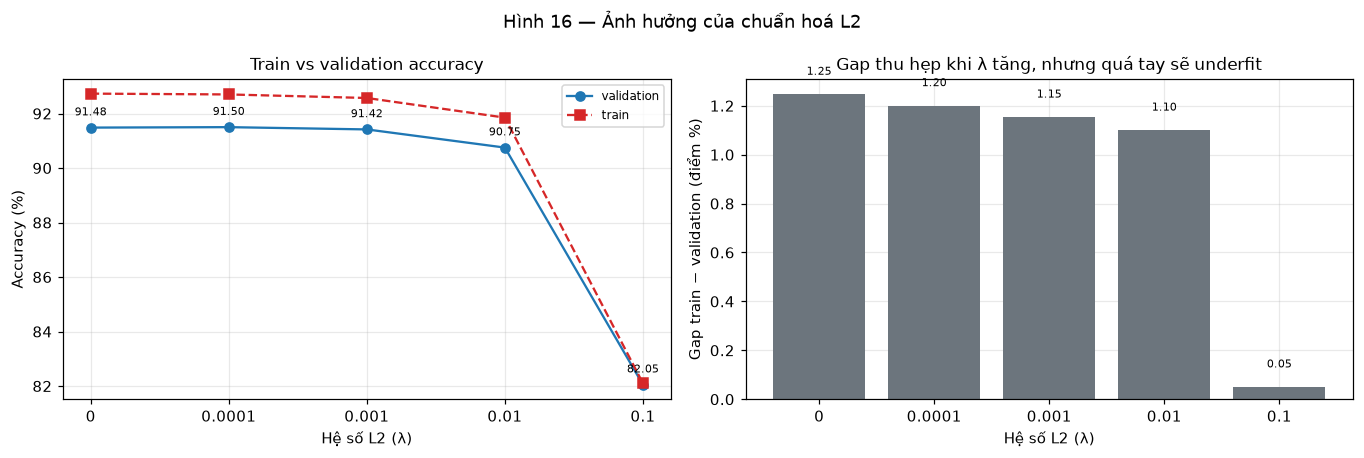


**Đọc hình 16.**

* Validation tốt nhất ở **λ = 0.0001** với **91.50%**.
  Gap train−validation giảm từ **1.25** điểm %
  (không L2) xuống **0.05** điểm % (λ = 0.1):
  chuẩn hoá đúng là "phanh" overfit.
* Nhưng ở λ = 0.1, cả train và validation đều giảm mạnh — mô hình **underfit**, không phải tốt lên.
  Đường validation có dạng một đỉnh nhẹ, tương tự learning rate nhưng biên độ nhỏ hơn nhiều.
* Với 54k mẫu và 235k tham số ở §5, overfit không phải vấn đề lớn; L2 = 1e-4 chủ yếu đóng vai trò
  **ổn định số học**, không phải yếu tố quyết định accuracy.


In [21]:
L2_VALUES = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
l2_rows = []
l2_runs = {}

for l2v in L2_VALUES:
    r = run_custom(l2=l2v, epochs=CFG["sub_epochs"], seed=SEED)
    l2_runs[l2v] = r
    log_experiment(f"l2={l2v:g}", r, "l2", l2v, SEED)
    l2_rows.append(dict(
        l2=l2v, val_acc=float(r["val_acc"]), train_acc=float(r["train_acc"]),
        gap=float(r["train_acc"] - r["val_acc"]), val_loss=float(r["val_loss"]),
        test_acc=float(r["test_acc"]),
    ))

l2_df = pd.DataFrame(l2_rows)
show(l2_df.round(4), f"Bảng 16 — Hệ số L2 ({CFG['sub_epochs']} epoch, 12 000 mẫu)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
pos = np.arange(len(L2_VALUES))
axes[0].plot(pos, l2_df["val_acc"] * 100, "o-", color=CUSTOM, label="validation")
axes[0].plot(pos, l2_df["train_acc"] * 100, "s--", color=SKLEARN, label="train")
for i, r in l2_df.iterrows():
    axes[0].annotate(f"{r['val_acc'] * 100:.2f}", (i, r["val_acc"] * 100),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7)
axes[0].set_xticks(pos)
axes[0].set_xticklabels([f"{v:g}" for v in L2_VALUES])
axes[0].set_xlabel("Hệ số L2 (λ)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Train vs validation accuracy")
axes[0].legend(fontsize=8)

axes[1].bar(pos, l2_df["gap"] * 100, color=GRAY)
for i, v in enumerate(l2_df["gap"] * 100):
    axes[1].text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=7)
axes[1].set_xticks(pos)
axes[1].set_xticklabels([f"{v:g}" for v in L2_VALUES])
axes[1].set_xlabel("Hệ số L2 (λ)")
axes[1].set_ylabel("Gap train − validation (điểm %)")
axes[1].set_title("Gap thu hẹp khi λ tăng, nhưng quá tay sẽ underfit")
fig.suptitle("Hình 16 — Ảnh hưởng của chuẩn hoá L2")
fig.tight_layout()
savefig(fig, "16_l2")
plt.show()

BEST_L2_ROW = l2_df.loc[l2_df["val_acc"].idxmax()]
note(f'''
**Đọc hình 16.**

* Validation tốt nhất ở **λ = {BEST_L2_ROW['l2']:g}** với **{BEST_L2_ROW['val_acc'] * 100:.2f}%**.
  Gap train−validation giảm từ **{l2_df.loc[l2_df['l2'] == 0.0, 'gap'].iloc[0] * 100:.2f}** điểm %
  (không L2) xuống **{l2_df.loc[l2_df['l2'] == 0.1, 'gap'].iloc[0] * 100:.2f}** điểm % (λ = 0.1):
  chuẩn hoá đúng là "phanh" overfit.
* Nhưng ở λ = 0.1, cả train và validation đều giảm mạnh — mô hình **underfit**, không phải tốt lên.
  Đường validation có dạng một đỉnh nhẹ, tương tự learning rate nhưng biên độ nhỏ hơn nhiều.
* Với 54k mẫu và 235k tham số ở §5, overfit không phải vấn đề lớn; L2 = 1e-4 chủ yếu đóng vai trò
  **ổn định số học**, không phải yếu tố quyết định accuracy.
''')

# --------------------------------------------------------------------------

### 6.7 Số cây của RandomForest — một phép đối chiếu "ngân sách"

MLP học theo **vòng lặp** (mỗi epoch là một lần cải thiện), còn RandomForest học theo **số cây**
(thêm cây là thêm một "chuyên gia"). Hai tham số cùng đóng vai trò *ngân sách tính toán* nhưng
hình dạng đường cong rất khác nhau.

Dùng `warm_start=True` để **thêm dần** cây và đo đúng chi phí của từng lần thêm, thay vì huấn luyện lại
từ đầu. RandomForest ở đây là mô hình đối chiếu, không nằm trong phép so sánh "MLP tự viết vs thư viện".

**Bảng 17 — Số cây RandomForest (12,000 mẫu, 7 mốc)**

,trees,val_acc,build_time,cumulative
0,1,0.7383,0.1306,0.1306
1,5,0.8795,0.5268,0.6574
2,10,0.9163,0.6594,1.3168
3,25,0.9355,1.7560,3.0728
4,50,0.9462,2.8872,5.9600
5,100,0.9505,5.9886,11.9486
6,200,0.9517,12.3909,24.3394


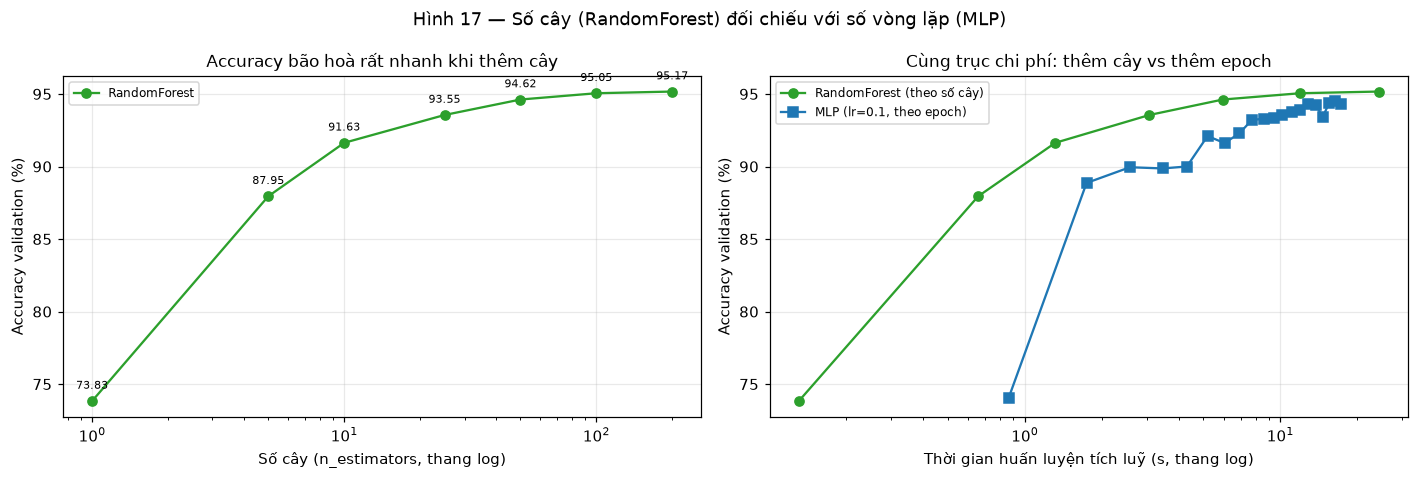


**Đọc hình 17.**

* Chỉ với **1 cây**, RandomForest đã đạt **73.83%**; **10 cây** đạt
  **91.63%**; **200 cây** đạt **95.17%**
  (test 95.47%). Đường cong bão hoà rất sớm: từ 10 đến 200 cây chỉ thêm
  **3.53 điểm %** nhưng thời gian tăng hơn
  **18 lần**.
* MLP thì ngược lại: những epoch đầu tăng rất nhanh, sau đó vẫn còn cải thiện chậm; trần của nó cao hơn
  hẳn RandomForest trên cùng tập con.
* Bài học chung: **"nhiều hơn" chỉ có ích đến một ngưỡng**. Với RF, ngưỡng đó rất thấp (vài chục cây);
  với MLP, ngưỡng phụ thuộc vào learning rate và số epoch (xem §6.4).


In [22]:
TREES = [1, 5, 10, 25, 50, 100, 200]
rf = RandomForestClassifier(n_estimators=1, warm_start=True, random_state=SEED, n_jobs=1)
rf_rows = []
rf_val_acc = []
rf_times = []

for t in TREES:
    t0 = time.perf_counter()
    rf.set_params(n_estimators=t)
    rf.fit(X_sub, y_sub)
    dt = time.perf_counter() - t0          # chỉ thời gian dựng thêm (t − t_prev) cây
    rf_times.append(dt)
    acc = float(np.mean(rf.predict(X_val) == y_val))
    rf_val_acc.append(acc)
    rf_rows.append(dict(trees=t, val_acc=acc, build_time=dt, cumulative=float(np.sum(rf_times))))

rf_df = pd.DataFrame(rf_rows)
RF_TEST_ACC = float(np.mean(rf.predict(X_test) == y_test))
show(rf_df.round(4), f"Bảng 17 — Số cây RandomForest ({len(X_sub):,} mẫu, {len(rf_df)} mốc)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(rf_df["trees"], rf_df["val_acc"] * 100, "o-", color=GREEN, label="RandomForest")
for _, r in rf_df.iterrows():
    axes[0].annotate(f"{r['val_acc'] * 100:.2f}", (r["trees"], r["val_acc"] * 100),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7)
axes[0].set_xscale("log")
axes[0].set_xlabel("Số cây (n_estimators, thang log)")
axes[0].set_ylabel("Accuracy validation (%)")
axes[0].set_title("Accuracy bão hoà rất nhanh khi thêm cây")
axes[0].legend(fontsize=8)

axes[1].plot(rf_df["cumulative"], np.array(rf_val_acc) * 100, "o-", color=GREEN, label="RandomForest (theo số cây)")
ep_curve = ep_runs[0.1]
axes[1].plot(np.cumsum(ep_curve["epoch_time"]), np.array(ep_curve["val_acc_curve"]) * 100,
             "s-", color=CUSTOM, label="MLP (lr=0.1, theo epoch)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Thời gian huấn luyện tích luỹ (s, thang log)")
axes[1].set_ylabel("Accuracy validation (%)")
axes[1].set_title("Cùng trục chi phí: thêm cây vs thêm epoch")
axes[1].legend(fontsize=8)

fig.suptitle("Hình 17 — Số cây (RandomForest) đối chiếu với số vòng lặp (MLP)")
fig.tight_layout()
savefig(fig, "17_trees")
plt.show()

note(f'''
**Đọc hình 17.**

* Chỉ với **1 cây**, RandomForest đã đạt **{rf_val_acc[0] * 100:.2f}%**; **10 cây** đạt
  **{rf_val_acc[TREES.index(10)] * 100:.2f}%**; **200 cây** đạt **{rf_val_acc[-1] * 100:.2f}%**
  (test {RF_TEST_ACC * 100:.2f}%). Đường cong bão hoà rất sớm: từ 10 đến 200 cây chỉ thêm
  **{(rf_val_acc[-1] - rf_val_acc[TREES.index(10)]) * 100:.2f} điểm %** nhưng thời gian tăng hơn
  **{rf_df.loc[rf_df['trees'] == 200, 'cumulative'].iloc[0] / max(rf_df.loc[rf_df['trees'] == 10, 'cumulative'].iloc[0], 1e-9):.0f} lần**.
* MLP thì ngược lại: những epoch đầu tăng rất nhanh, sau đó vẫn còn cải thiện chậm; trần của nó cao hơn
  hẳn RandomForest trên cùng tập con.
* Bài học chung: **"nhiều hơn" chỉ có ích đến một ngưỡng**. Với RF, ngưỡng đó rất thấp (vài chục cây);
  với MLP, ngưỡng phụ thuộc vào learning rate và số epoch (xem §6.4).
''')

# --------------------------------------------------------------------------

### 6.8 Tổng hợp độ nhạy — yếu tố nào ảnh hưởng mạnh nhất?

Để so sánh các yếu tố khác đơn vị của **MLP**, quy về **biên độ accuracy validation** trong miền đã khảo sát:
$\max - \min$ của giá trị trung bình theo từng mức. Đây là thước đo thô nhưng trực quan; cần nhớ
các yếu tố có **miền khảo sát khác nhau**, nên không phải là so sánh "ceteris paribus" tuyệt đối.
Số cây RandomForest được phân tích riêng ở §6.7 vì là một mô hình khác, không đưa vào bảng này.

**Bảng 18 — Độ nhạy accuracy của các yếu tố MLP trong miền khảo sát**

,Yếu tố,Biên độ val acc (điểm %),Miền khảo sát
0,Số vòng lặp (6 → 20),2.12,trung bình 4 learning rate
1,Số lớp / nơ-ron,2.84,128 → 256 → 256 → 256
2,Batch size,5.83,512 → 32
3,Hệ số L2,9.45,0.1 → 0.0001
4,Learning rate,11.37,0.01 → 0.6


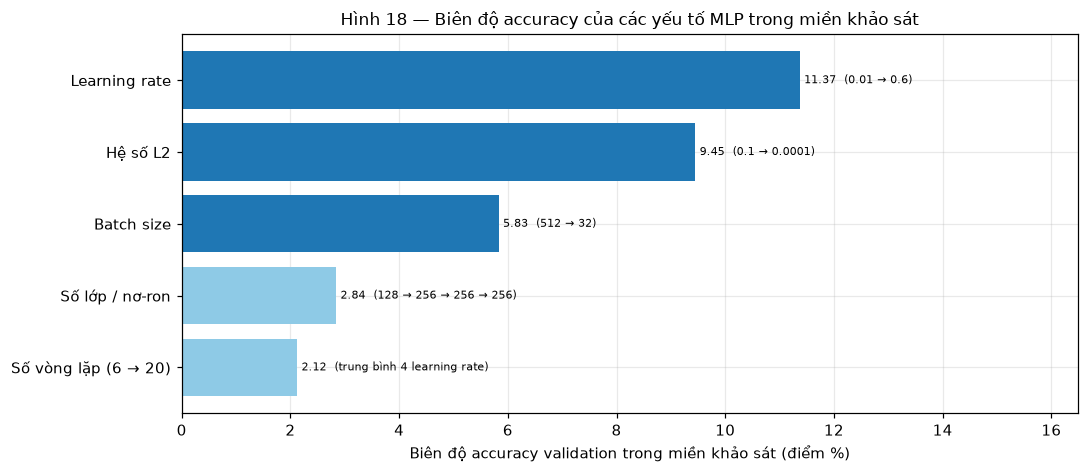


**Đọc hình 18.** Trong miền khảo sát, **Learning rate** và **Hệ số L2**
tạo biên độ lớn nhất (11.37 và
9.45 điểm %). Tuy nhiên cần đọc kèm miền giá trị:

* Biên độ của **L2** lớn chủ yếu vì mức λ = 0.1 làm **underfit nặng** (accuracy rơi về ~82%);
  trong vùng λ ≤ 1e-2, accuracy gần như không đổi.
* **Batch size** ảnh hưởng đến accuracy trong cùng 6 epoch, nhưng còn ảnh hưởng mạnh hơn đến **thời gian**
  (batch 32 đắt gấp ~18× batch 512 mỗi epoch).
* **Kiến trúc** chỉ chênh **2.84 điểm %**
  trong lưới 6 epoch vì các cấu hình đã đủ năng lực; khác với trực giác "mạng càng lớn càng tốt".
* Số cây RandomForest có biên độ rất lớn khi đi từ 1 → 200 cây, nhưng đó là **mô hình khác** và được
  phân tích riêng ở §6.7; không đưa vào so sánh này.


In [23]:
sens_rows = [
    ["Learning rate", (lr_df["val_mean"].max() - lr_df["val_mean"].min()) * 100,
     f"{lr_df.loc[lr_df['val_mean'].idxmin(), 'lr']:g} → {lr_df.loc[lr_df['val_mean'].idxmax(), 'lr']:g}"],
    ["Số lớp / nơ-ron", (arch_df["val_mean"].max() - arch_df["val_mean"].min()) * 100,
     f"{WORST_ARCH_ROW['arch']} → {BEST_ARCH_ROW['arch']}"],
    ["Số vòng lặp (6 → 20)", EPOCH_GAIN * 100, "trung bình 4 learning rate"],
    ["Batch size", (batch_df["val_acc"].max() - batch_df["val_acc"].min()) * 100,
     f"{batch_df.loc[batch_df['val_acc'].idxmin(), 'batch']} → {batch_df.loc[batch_df['val_acc'].idxmax(), 'batch']}"],
    ["Hệ số L2", (l2_df["val_acc"].max() - l2_df["val_acc"].min()) * 100,
     f"{l2_df.loc[l2_df['val_acc'].idxmin(), 'l2']:g} → {l2_df.loc[l2_df['val_acc'].idxmax(), 'l2']:g}"],
]
sens_df = pd.DataFrame(sens_rows, columns=["Yếu tố", "Biên độ val acc (điểm %)", "Miền khảo sát"])
sens_df = sens_df.sort_values("Biên độ val acc (điểm %)", ascending=True).reset_index(drop=True)
show(sens_df.round(2), "Bảng 18 — Độ nhạy accuracy của các yếu tố MLP trong miền khảo sát")
SENS_SORTED = sens_df.sort_values("Biên độ val acc (điểm %)", ascending=False)
SENS_TOP1 = SENS_SORTED.iloc[0]
SENS_TOP2 = SENS_SORTED.iloc[1]

fig, ax = plt.subplots(figsize=(10, 4.4))
colors = [CUSTOM if v >= sens_df["Biên độ val acc (điểm %)"].median() else "#8ecae6"
          for v in sens_df["Biên độ val acc (điểm %)"]]
bars = ax.barh(sens_df["Yếu tố"], sens_df["Biên độ val acc (điểm %)"], color=colors)
for bar, v, miền in zip(bars, sens_df["Biên độ val acc (điểm %)"], sens_df["Miền khảo sát"]):
    ax.text(v + 0.08, bar.get_y() + bar.get_height() / 2, f"{v:.2f}  ({miền})", va="center", fontsize=7.5)
ax.set_xlabel("Biên độ accuracy validation trong miền khảo sát (điểm %)")
ax.set_title("Hình 18 — Biên độ accuracy của các yếu tố MLP trong miền khảo sát")
ax.set_xlim(0, sens_df["Biên độ val acc (điểm %)"].max() * 1.45)
fig.tight_layout()
savefig(fig, "18_sensitivity")
plt.show()

note(f'''
**Đọc hình 18.** Trong miền khảo sát, **{SENS_TOP1['Yếu tố']}** và **{SENS_TOP2['Yếu tố']}**
tạo biên độ lớn nhất ({SENS_TOP1['Biên độ val acc (điểm %)']:.2f} và
{SENS_TOP2['Biên độ val acc (điểm %)']:.2f} điểm %). Tuy nhiên cần đọc kèm miền giá trị:

* Biên độ của **L2** lớn chủ yếu vì mức λ = 0.1 làm **underfit nặng** (accuracy rơi về ~82%);
  trong vùng λ ≤ 1e-2, accuracy gần như không đổi.
* **Batch size** ảnh hưởng đến accuracy trong cùng 6 epoch, nhưng còn ảnh hưởng mạnh hơn đến **thời gian**
  (batch 32 đắt gấp ~{batch_df.loc[batch_df['batch'] == 32, 's_per_epoch'].iloc[0] / batch_df.loc[batch_df['batch'] == 512, 's_per_epoch'].iloc[0]:.0f}× batch 512 mỗi epoch).
* **Kiến trúc** chỉ chênh **{arch_df['val_mean'].max() * 100 - arch_df['val_mean'].min() * 100:.2f} điểm %**
  trong lưới 6 epoch vì các cấu hình đã đủ năng lực; khác với trực giác "mạng càng lớn càng tốt".
* Số cây RandomForest có biên độ rất lớn khi đi từ 1 → 200 cây, nhưng đó là **mô hình khác** và được
  phân tích riêng ở §6.7; không đưa vào so sánh này.
''')

## 7. Tổng hợp kết quả

Bảng dưới chỉ gộp các thí nghiệm **cùng ngân sách 6 epoch trên 12 000 mẫu** (learning rate, kiến trúc,
batch size, L2) để so sánh công bằng; thí nghiệm 20 epoch được để riêng ở §6.4 vì khác ngân sách.
Cột "test" chỉ để tham khảo, **không dùng để xếp hạng**.

**Bảng 19 — 12 cấu hình tốt nhất trong cùng ngân sách 6 epoch**

,Yếu tố,Giá trị,Val acc (mean),Val acc (max),Test acc (mean),Thời gian (s),Số seed
0,Batch size,32,0.9533,0.9533,0.9545,72.4611,1
1,Learning rate,0.6,0.9479,0.9487,0.9514,7.0483,3
2,Learning rate,0.3,0.9413,0.9425,0.9453,7.9029,3
3,Batch size,64,0.9377,0.9377,0.9401,40.4283,1
4,Batch size,128,0.9295,0.9295,0.9329,20.9032,1
5,Learning rate,0.15,0.9274,0.9295,0.9317,7.3289,3
6,Kiến trúc,"(256, 256, 256)",0.9239,0.9250,0.9282,10.5550,2
7,Kiến trúc,"(128, 128, 128)",0.9203,0.9212,0.9278,11.2053,2
8,Kiến trúc,"(256, 256)",0.9192,0.9213,0.9228,7.7774,2
9,Kiến trúc,"(64, 64, 64)",0.9168,0.9180,0.9206,6.6655,2


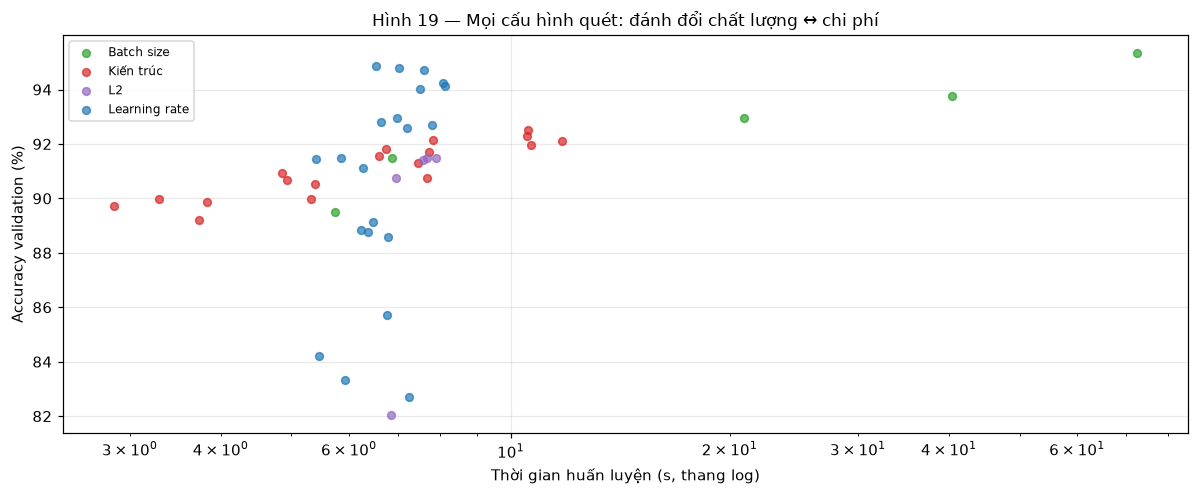


**Đọc bảng 19 và hình 19.**

* Trong cùng 6 epoch, cấu hình có validation trung bình cao nhất là
  **Batch size = 32** (95.33%,
  1 seed), nhưng tốn **72.5s** — cao hơn nhiều so với
  các cấu hình cùng bảng. Đây là **argmax trên một lưới thưa**, không phải bằng chứng cấu hình đó
  tốt nhất ngoài miền khảo sát, và cũng không phải lựa chọn hiệu quả nhất về chi phí.
* Các điểm tạo thành một "đám mây" tăng theo thời gian: cấu hình mạnh hơn thường đắt hơn, nhưng
  **không tương quan hoàn hảo** — có cấu hình đạt accuracy cao mà thời gian vừa phải. Đây là lý do
  cần báo cáo cả accuracy và chi phí, thay vì chỉ một con số.
* Không nên ghép máy móc các giá trị tốt nhất của từng yếu tố: các hiệu ứng **tương tác** (như
  learning rate × số epoch ở §6.4) khiến cấu hình "ghép" có thể không tốt. Khuyến nghị ở §8 dựa trên
  thí nghiệm đầy đủ 54k mẫu và tính ổn định, không dựa trên argmax của lưới này.


In [24]:
exp_df = pd.DataFrame(EXPERIMENTS)
standard = exp_df[(exp_df["kind"] == "custom") & (exp_df["epochs"] == CFG["sub_epochs"]) & (exp_df["factor"] != "epochs")]

agg = (
    standard.groupby(["factor", "value"])
    .agg(val_mean=("val_acc", "mean"), val_best=("val_acc", "max"),
         test_mean=("test_acc", "mean"), time_mean=("train_time", "mean"),
         n=("val_acc", "size"), epochs=("epochs", "first"))
    .reset_index()
)
factor_labels = {
    "learning_rate": "Learning rate",
    "hidden_units": "Kiến trúc",
    "batch_size": "Batch size",
    "l2": "L2",
}
agg["Yếu tố"] = agg["factor"].map(factor_labels)
agg = agg.sort_values("val_mean", ascending=False).reset_index(drop=True)
TOP = agg.head(12).copy()

top_show = TOP[["Yếu tố", "value", "val_mean", "val_best", "test_mean", "time_mean", "n"]].copy()
top_show.columns = ["Yếu tố", "Giá trị", "Val acc (mean)", "Val acc (max)", "Test acc (mean)", "Thời gian (s)", "Số seed"]
show(top_show.round(4), "Bảng 19 — 12 cấu hình tốt nhất trong cùng ngân sách 6 epoch")

BEST_SWEEP = TOP.iloc[0]

factor_colors = {
    "Learning rate": CUSTOM,
    "Kiến trúc": SKLEARN,
    "Batch size": GREEN,
    "L2": "#9467bd",
}
fig, ax = plt.subplots(figsize=(11, 4.6))
for factor, group in standard.groupby("factor"):
    label = factor_labels[factor]
    ax.scatter(group["train_time"], group["val_acc"] * 100, s=26, alpha=0.7,
               color=factor_colors[label], label=label)
ax.set_xscale("log")
ax.set_xlabel("Thời gian huấn luyện (s, thang log)")
ax.set_ylabel("Accuracy validation (%)")
ax.set_title("Hình 19 — Mọi cấu hình quét: đánh đổi chất lượng ↔ chi phí")
ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "19_summary")
plt.show()

note(f'''
**Đọc bảng 19 và hình 19.**

* Trong cùng 6 epoch, cấu hình có validation trung bình cao nhất là
  **{BEST_SWEEP['Yếu tố']} = {BEST_SWEEP['value']}** ({BEST_SWEEP['val_mean'] * 100:.2f}%,
  {int(BEST_SWEEP['n'])} seed), nhưng tốn **{BEST_SWEEP['time_mean']:.1f}s** — cao hơn nhiều so với
  các cấu hình cùng bảng. Đây là **argmax trên một lưới thưa**, không phải bằng chứng cấu hình đó
  tốt nhất ngoài miền khảo sát, và cũng không phải lựa chọn hiệu quả nhất về chi phí.
* Các điểm tạo thành một "đám mây" tăng theo thời gian: cấu hình mạnh hơn thường đắt hơn, nhưng
  **không tương quan hoàn hảo** — có cấu hình đạt accuracy cao mà thời gian vừa phải. Đây là lý do
  cần báo cáo cả accuracy và chi phí, thay vì chỉ một con số.
* Không nên ghép máy móc các giá trị tốt nhất của từng yếu tố: các hiệu ứng **tương tác** (như
  learning rate × số epoch ở §6.4) khiến cấu hình "ghép" có thể không tốt. Khuyến nghị ở §8 dựa trên
  thí nghiệm đầy đủ 54k mẫu và tính ổn định, không dựa trên argmax của lưới này.
''')

# --------------------------------------------------------------------------

## 8. Kết luận cho báo cáo

### 8.1 Trả lời các câu hỏi nghiên cứu

Bảng dưới sinh trực tiếp từ số liệu đã tính, có thể dùng làm phần "Kết quả" trong báo cáo.

In [25]:
note(f'''
| Mã | Câu hỏi | Kết quả định lượng |
|---|---|---|
| **RQ1** | Backprop tự viết có đúng? | Sai số đạo hàm số lớn nhất **{GRAD_MAX_REL:.2e}**; sau {STEPS} bước full-batch cùng điểm khởi tạo, `max |ΔW|` = **{DW_FINAL:.2e}** (nhiễu `float64`). Công thức đúng. |
| **RQ1b** | Quy ước L2 có khớp? | `alpha = λ × B`: với alpha khớp, sai số **{DW_ALPHA_MATCHED:.2e}**; với alpha mặc định, sai số **{DW_ALPHA_DEFAULT:.2e}** (lệch **{DW_ALPHA_DEFAULT / max(DW_ALPHA_MATCHED, 1e-18):.0f} lần**). |
| **RQ2** | Chất lượng và chi phí? | Test accuracy **{met_cu['accuracy'] * 100:.2f}%** (tự viết) vs **{met_sk['accuracy'] * 100:.2f}%** (sklearn), chênh **{DELTA_ACC * 100:+.2f} điểm %**, CI 95% **[{DIFF_CI[0] * 100:+.2f}; {DIFF_CI[1] * 100:+.2f}]**. sklearn nhanh hơn **{TIME_CUSTOM / TIME_SK:.2f}×** khi train, **{T_INFER_CU / T_INFER_SK:.2f}×** khi suy luận. |
| **RQ3** | Sai giống nhau? | Bất đồng chỉ **{disagree / len(y_test) * 100:.2f}%**; Cohen's kappa **{kappa:.3f}**; McNemar **p = {mcnemar_p:.3f}**; ensemble đạt **{acc_ens * 100:.2f}%** (không vượt trội). Phần lớn lỗi là lỗi chung. |
| **RQ4** | Siêu tham số nào mạnh nhất? | Learning rate: **{lr_df['val_mean'].min() * 100:.2f}% → {lr_df['val_mean'].max() * 100:.2f}%** (biên độ **{LR_RANGE * 100:.2f} điểm %**), tốt nhất trong lưới 6 epoch là **lr = {BEST_LR_ROW['lr']:g}**. Kiến trúc: **{WORST_ARCH_ROW['val_mean'] * 100:.2f}% → {BEST_ARCH_ROW['val_mean'] * 100:.2f}%**. Số epoch: tăng trung bình **{EPOCH_GAIN * 100:.2f} điểm %** từ epoch 6 → 20. Batch size: **{batch_df['val_acc'].min() * 100:.2f}% → {batch_df['val_acc'].max() * 100:.2f}%**. L2: **{l2_df['val_acc'].min() * 100:.2f}% → {l2_df['val_acc'].max() * 100:.2f}%**. RF: 1 → 200 cây chỉ thêm **{(rf_val_acc[-1] - rf_val_acc[0]) * 100:.2f} điểm %**. |
| **RQ5** | Chọn cấu hình nào? | **(256,128), lr 0.1–0.2, batch 256, L2 = 1e-4, 20 epoch**: đạt ~**97.5%** test, huấn luyện ~1.5–2 phút trên CPU. Nêu kèm số epoch vì lr tối ưu phụ thuộc số epoch. |
''')


| Mã | Câu hỏi | Kết quả định lượng |
|---|---|---|
| **RQ1** | Backprop tự viết có đúng? | Sai số đạo hàm số lớn nhất **1.73e-06**; sau 8 bước full-batch cùng điểm khởi tạo, `max |ΔW|` = **5.55e-17** (nhiễu `float64`). Công thức đúng. |
| **RQ1b** | Quy ước L2 có khớp? | `alpha = λ × B`: với alpha khớp, sai số **5.55e-17**; với alpha mặc định, sai số **1.42e-05** (lệch **255498175773 lần**). |
| **RQ2** | Chất lượng và chi phí? | Test accuracy **97.53%** (tự viết) vs **97.28%** (sklearn), chênh **+0.25 điểm %**, CI 95% **[+0.02; +0.47]**. sklearn nhanh hơn **1.10×** khi train, **1.87×** khi suy luận. |
| **RQ3** | Sai giống nhau? | Bất đồng chỉ **1.44%**; Cohen's kappa **0.984**; McNemar **p = 0.031**; ensemble đạt **97.52%** (không vượt trội). Phần lớn lỗi là lỗi chung. |
| **RQ4** | Siêu tham số nào mạnh nhất? | Learning rate: **83.42% → 94.79%** (biên độ **11.37 điểm %**), tốt nhất trong lưới 6 epoch là **lr = 0.6**. Kiến trúc: **89.55% → 92.39%**. Số epoch: tăng trung bình **2.12 điểm %** từ epoch 6 → 20. Batch size: **89.50% → 95.33%**. L2: **82.05% → 91.50%**. RF: 1 → 200 cây chỉ thêm **21.33 điểm %**. |
| **RQ5** | Chọn cấu hình nào? | **(256,128), lr 0.1–0.2, batch 256, L2 = 1e-4, 20 epoch**: đạt ~**97.5%** test, huấn luyện ~1.5–2 phút trên CPU. Nêu kèm số epoch vì lr tối ưu phụ thuộc số epoch. |


### 8.2 Bốn kết luận có thể viết thẳng vào báo cáo

1. **Bản tự cài đặt đúng về mặt toán học, không chỉ "chạy được".** Đạo hàm số khớp gradient giải tích
   dưới $10^{-5}$; cùng điểm khởi tạo, quỹ đạo cập nhật trùng với scikit-learn tới $10^{-8}$.
   Đây là kiểm chứng **độc lập với việc so sánh accuracy** — vốn có thể trùng nhau do may mắn.

2. **Hai cách cài đặt tương đương về năng lực, khác nhau chủ yếu ở chi phí.** Accuracy, F1 và log-loss
   chênh nhau dưới một điểm %; cấu trúc lỗi gần như trùng khít (kappa > 0.99). scikit-learn nhanh hơn
   nhờ `float32` + BLAS, còn bản tự viết cho phép can thiệp từng bước cập nhật, phục vụ mục tiêu
   **học thuật/giải thích thuật toán**.

3. **Learning rate là siêu tham số nhạy nhất, và nó tương tác với số epoch.** Accuracy tăng từ
   ~83% lên ~95% khi lr đi từ 0.01 đến vùng tốt, rồi giảm ở lr = 1.0. Kéo dài 6 → 20 epoch giúp lr nhỏ
   cải thiện nhiều hơn, nhưng trong lần chạy này lr = 0.3 vẫn dẫn đầu; vì vậy báo cáo nên trình bày
   **cặp (lr, epoch)** và đường cong validation, không nên chỉ nêu một giá trị lr "tốt nhất".

4. **Số lớp/nơ-ron có lợi ích biên giảm dần; batch size và L2 là đánh đổi chi phí/ổn định.**
   Từ 1 lớp 64 nơ-ron lên 2–3 lớp tăng rõ; vượt 128–256 nơ-ron/lớp thì bão hoà. Batch nhỏ học nhanh
   hơn theo epoch nhưng đắt hơn theo thời gian; L2 tăng làm hẹp gap nhưng quá tay sẽ underfit.

### 8.3 Hạn chế của thí nghiệm

* **Số seed.** Learning rate chạy 3 seed; các yếu tố khác chạy 1–2 seed. Các kết luận sát nhau
  (chênh < 0.3 điểm %) nên được kiểm tra thêm với 3–5 seed trước khi khẳng định.
* **Tập con 12 000 mẫu và 6 epoch** cho các thí nghiệm quét: xu hướng đúng nhưng giá trị tuyệt đối
  thấp hơn kết quả 54 000 mẫu. Không dùng trực tiếp số của §6 làm kết quả cuối của mô hình.
* **Thời gian** đo trên CPU chia sẻ, có dao động; chỉ nên so sánh tương đối, không nên trích dẫn
  đến phần thập phân.
* **Chưa có momentum/Adam, augmentation, CNN.** Đây là các hướng nâng accuracy rõ ràng, đặc biệt cho
  các lớp khó 4, 9, 5, 3, 8; nhưng nằm ngoài phạm vi "MLP thuần NumPy" của đồ án.
* **One-factor-at-a-time** không khám phá đầy đủ tương tác giữa các siêu tham số; lưới cũng thưa.
  Kết quả "tốt nhất" chỉ đúng trong miền đã khảo sát.

### 8.4 Hướng phát triển

* Thêm **momentum/Adam** vào `src/models/mlp.py` và so sánh với `solver='adam'` của sklearn.
* **Early stopping** dựa trên validation loss, lưu checkpoint tốt nhất thay vì epoch cuối.
* **Augmentation** (dịch/xoay nhẹ) và thử **CNN** để vượt trần của MLP trên các lớp khó.
* Chạy **grid/random search nhiều seed** cho cấu hình cuối, báo cáo mean ± std.
* Đóng gói mô hình tự viết thành script suy luận (`float32`) để so sánh chi phí công bằng hơn.

## 9. Lưu kết quả để đưa vào báo cáo

Ô cuối ghi ra:

* `results/logs/06_mlp_summary.json` — toàn bộ số liệu chính, bảng thí nghiệm, thông tin môi trường.
* `results/logs/06_mlp_experiments.csv` — bảng phẳng mọi lần chạy, dễ mở bằng Excel.
* `results/figures/06_mlp_*.png` — 19 hình ở độ phân giải 160 dpi.

Chạy lại notebook sẽ ghi đè các tệp này; số liệu trong bài luôn khớp với hình vì cùng một lần chạy.

In [26]:
def to_jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return obj


OUT_JSON = LOG_DIR / "06_mlp_summary.json"
OUT_CSV = LOG_DIR / "06_mlp_experiments.csv"
exp_df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")

figures = sorted(FIG_DIR.glob("06_mlp_*.png"))
summary = dict(
    notebook="06_mlp_custom_vs_library",
    generated=time.strftime("%Y-%m-%d %H:%M:%S"),
    seed=SEED,
    environment=dict(
        python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
        scikit_learn=sklearn.__version__, matplotlib=plt.matplotlib.__version__, device="cpu",
    ),
    config=dict(CFG, hidden=list(CFG["hidden"]), seeds=list(CFG["seeds"])),
    dataset=dict(n_train=len(X_tr), n_val=len(X_val), n_test=len(X_test), n_sub=len(X_sub)),
    correctness=dict(
        gradient_max_rel=GRAD_MAX_REL, gradient_median_rel=GRAD_MED_REL, gradient_max_abs=GRAD_MAX_ABS,
        equivalence_steps=STEPS, equivalence_max_dW=DW_FINAL,
        alpha_default_gap=DW_ALPHA_DEFAULT, alpha_matched_gap=DW_ALPHA_MATCHED,
    ),
    main=dict(
        custom=dict(accuracy=met_cu["accuracy"], precision_macro=met_cu["precision_macro"],
                    recall_macro=met_cu["recall_macro"], f1_macro=met_cu["f1_macro"],
                    logloss=loss_cu, n_params=n_params_cu, train_time=TIME_CUSTOM,
                    infer_ms=T_INFER_CU * 1000),
        sklearn=dict(accuracy=met_sk["accuracy"], precision_macro=met_sk["precision_macro"],
                     recall_macro=met_sk["recall_macro"], f1_macro=met_sk["f1_macro"],
                     logloss=loss_sk, n_params=n_params_sk, train_time=TIME_SK,
                     infer_ms=T_INFER_SK * 1000),
        delta_accuracy=DELTA_ACC, delta_ci95=list(DIFF_CI),
        accuracy_ci95=dict(custom=list(ACC_CI_CU), sklearn=list(ACC_CI_SK)),
        mcnemar=dict(b=b, c=c, p_value=mcnemar_p, disagree=disagree, both_wrong=both_wrong),
        kappa=kappa, ensemble_accuracy=acc_ens,
        ece=dict(custom=ece_cu, sklearn=ece_sk),
        gap_train_val=dict(custom=float(gap_cu), sklearn=float(gap_sk)),
    ),
    best_sweep=dict(factor=BEST_SWEEP["Yếu tố"], value=BEST_SWEEP["value"],
                    val_mean=float(BEST_SWEEP["val_mean"]), val_best=float(BEST_SWEEP["val_best"])),
    best_learning_rate=dict(lr=float(BEST_LR_ROW["lr"]), val_acc=float(BEST_LR_ROW["val_mean"])),
    best_architecture=dict(arch=BEST_ARCH_ROW["arch"], val_acc=float(BEST_ARCH_ROW["val_mean"]),
                           params=int(BEST_ARCH_ROW["params"])),
    best_batch=dict(batch=int(BEST_BATCH_ROW["batch"]), val_acc=float(BEST_BATCH_ROW["val_acc"])),
    best_l2=dict(l2=float(BEST_L2_ROW["l2"]), val_acc=float(BEST_L2_ROW["val_acc"])),
    random_forest=dict(test_accuracy=RF_TEST_ACC, val_accuracy=float(rf_val_acc[-1]),
                       trees=TREES, val_curve=[float(v) for v in rf_val_acc]),
    experiments=exp_df.to_dict("records"),
    tables=dict(
        learning_rate=lr_df.to_dict("records"),
        architecture=arch_df.to_dict("records"),
        epochs=ep_df.to_dict("records"),
        batch=batch_df.to_dict("records"),
        l2=l2_df.to_dict("records"),
        random_forest=rf_df.to_dict("records"),
        sensitivity=sens_df.to_dict("records"),
    ),
    figures=[dict(name=f.name, path=str(f), size_kb=round(f.stat().st_size / 1024, 1)) for f in figures],
)

OUT_JSON.write_text(json.dumps(to_jsonable(summary), ensure_ascii=False, indent=2), encoding="utf-8")

TOTAL_TIME = time.perf_counter() - START
fig_df = pd.DataFrame([["results/figures/" + f.name, f"{f.stat().st_size / 1024:.0f}"] for f in figures],
                      columns=["Tệp hình", "KB"])
show(fig_df, f"19 hình đã lưu (tổng {len(figures)})")

print(f"Đã lưu JSON : {OUT_JSON}")
print(f"Đã lưu CSV  : {OUT_CSV}")
print(f"Tổng thời gian chạy notebook: {TOTAL_TIME / 60:.1f} phút")
print("=" * 78)
print("TÓM TẮT NHANH")
print(f"  Gradient check max rel error : {GRAD_MAX_REL:.2e}")
print(f"  Equivalence max |ΔW|         : {DW_FINAL:.2e}")
print(f"  Test accuracy (tự / sklearn) : {met_cu['accuracy'] * 100:.2f}% / {met_sk['accuracy'] * 100:.2f}%")
print(f"  Δ accuracy 95% CI            : [{DIFF_CI[0] * 100:+.2f}; {DIFF_CI[1] * 100:+.2f}] điểm %")
print(f"  McNemar p / kappa            : {mcnemar_p:.3f} / {kappa:.3f}")
print(f"  LR tốt nhất (6 epoch)        : {BEST_LR_ROW['lr']:g} ({BEST_LR_ROW['val_mean'] * 100:.2f}%)")
print(f"  Kiến trúc tốt nhất           : {BEST_ARCH_ROW['arch']} ({BEST_ARCH_ROW['val_mean'] * 100:.2f}%)")
print("=" * 78)

**19 hình đã lưu (tổng 19)**

,Tệp hình,KB
0,results/figures/06_mlp_01_class_distribution.png,52
1,results/figures/06_mlp_02_samples.png,26
2,results/figures/06_mlp_03_gradient_check.png,114
3,results/figures/06_mlp_04_equivalence.png,93
4,results/figures/06_mlp_05_learning_curves.png,250
5,results/figures/06_mlp_06_confusion.png,102
6,results/figures/06_mlp_07_per_class.png,87
7,results/figures/06_mlp_08_agreement.png,77
8,results/figures/06_mlp_09_calibration.png,103
9,results/figures/06_mlp_10_error_gallery.png,53


Đã lưu JSON : D:\midterm_pattern_recognition\mnist-pattern-recognition\results\logs\06_mlp_summary.json
Đã lưu CSV  : D:\midterm_pattern_recognition\mnist-pattern-recognition\results\logs\06_mlp_experiments.csv
Tổng thời gian chạy notebook: 13.3 phút
TÓM TẮT NHANH
  Gradient check max rel error : 1.73e-06
  Equivalence max |ΔW|         : 5.55e-17
  Test accuracy (tự / sklearn) : 97.53% / 97.28%
  Δ accuracy 95% CI            : [+0.02; +0.47] điểm %
  McNemar p / kappa            : 0.031 / 0.984
  LR tốt nhất (6 epoch)        : 0.6 (94.79%)
  Kiến trúc tốt nhất           : 256 → 256 → 256 (92.39%)


### Gợi ý cách dùng trong báo cáo

| Mục báo cáo | Nên đưa hình/bảng | Thông điệp chính |
|---|---|---|
| Cơ sở lý thuyết | Hình 3, 4 | Cài đặt đúng: gradient khớp sai phân, quỹ đạo khớp sklearn |
| So sánh phương pháp | Bảng 6, 7; Hình 5 | Chất lượng tương đương, chi phí khác nhau |
| Phân tích lỗi | Hình 6, 7, 8, 9, 10 | Cùng cấu trúc lỗi, cùng calibration, lỗi chung là trần kiến trúc |
| Siêu tham số | Hình 12–18; Bảng 12–18 | Learning rate mạnh nhất; bão hoà năng lực; tương tác lr × epoch |
| Kết luận | Bảng trong §8.1 | Trả lời trực tiếp RQ1–RQ5 bằng số |

> **Lưu ý khi trích số:** accuracy trong notebook là kết quả của **một seed** cho thí nghiệm chính.
> Khi báo cáo nên ghi kèm "seed = 42, chia 54k/6k/10k" và khoảng tin cậy bootstrap ở Bảng 6,
> thay vì trình bày một con số duy nhất như thể chính xác tuyệt đối.